# Notebook 3 — Adaptive Monitoring and Early-Warning Detection

This notebook evaluates whether a realistic monitoring framework can detect and diagnose deterioration in a previously valid frozen model.

The monitoring system does not know which experimental path generated the data.

The notebook focuses on:

- input-distribution monitoring;
- delayed realized-performance monitoring;
- sequential early-warning detection;
- false alarms;
- detection delay;
- diagnosis of input shift versus model deterioration.

The frozen baseline model from Notebook 1 is never retrained or recalibrated here.

## Experimental design

The monitoring experiment uses 36 monthly periods.

- Months 1–12: healthy pre-change operation
- Months 13–24: change onset and transition
- Months 25–36: sustained mature environment

Each month contains a new cohort of 3,000 borrowers.

Normal 12-month seasonality is present throughout the experiment.

Outcome-dependent monitoring metrics are available with a three-month delay.

Five evaluation paths will eventually be considered:

1. Seasonal Stable
2. Gradual Covariate Shift
3. Gradual Concept Deterioration
4. Gradual Combined Shift
5. Abrupt Regime Shock

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.drift import summarize_feature_drift
from src.monitoring import (
    apply_persistence_rule,
    calculate_calibration_error,
    calculate_detection_delay,
    calculate_empirical_threshold,
    calculate_ewma,
    calculate_null_percentile,
    calculate_performance_metrics,
    calculate_system_score,
)

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk


In [2]:
MODEL_PATH = PROJECT_ROOT / "models" / "baseline_model.joblib"

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Baseline model not found: {MODEL_PATH}"
    )

baseline_model = joblib.load(MODEL_PATH)

print(f"Loaded baseline model: {MODEL_PATH}")
print(baseline_model)

Loaded baseline model: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\models\baseline_model.joblib
Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic_regression',
                 LogisticRegression(max_iter=1000, random_state=42))])


In [3]:
MODEL_FEATURES = list(baseline_model.feature_names_in_)

print("Model features:")
for feature in MODEL_FEATURES:
    print(f"  - {feature}")

Model features:
  - credit_score
  - debt_to_income
  - loan_to_income
  - unemployment_rate


In [4]:
# Core monitoring timeline
N_PERIODS = 36
MONTHS_PER_YEAR = 12
DRIFT_ONSET_PERIOD = 13

# Monthly cohort
MONTHLY_COHORT_SIZE = 3_000

# Outcome-label availability
LABEL_DELAY = 3

# Gradual deterioration targets
MAX_CREDIT_SCORE_SHIFT = -20.0
MAX_DTI_SHIFT = 0.05
MAX_CONCEPT_LOG_ODDS_SHIFT = 0.60

# Abrupt regime-shock targets
SHOCK_UNEMPLOYMENT_SHIFT = 0.02
BASELINE_UNEMPLOYMENT_COEF = 0.45
SHOCK_UNEMPLOYMENT_COEF = 0.75

# Candidate healthy seasonal amplitudes
UNEMPLOYMENT_SEASONAL_AMPLITUDE = 0.003
DTI_SEASONAL_AMPLITUDE = 0.015

# Seasonal phase offsets
UNEMPLOYMENT_PHASE = 1
DTI_PHASE = 4

# Monitoring configuration
EWMA_LAMBDA = 0.30
RAW_FLAG_QUANTILE = 0.99
PERSISTENCE_WINDOW = 3
PERSISTENCE_REQUIRED = 2

# Null calibration
N_NULL_TRAJECTORIES = 2_000

# Reproducibility
REFERENCE_SEED = 10_001
NULL_SIMULATION_SEED = 20_001
EVALUATION_SEED = 30_001

REFERENCE_COHORT_SIZE = 50_000

assert N_PERIODS == 36
assert DRIFT_ONSET_PERIOD == 13
assert LABEL_DELAY >= 0
assert MONTHLY_COHORT_SIZE > 0
assert 0 < EWMA_LAMBDA <= 1
assert 0 < RAW_FLAG_QUANTILE < 1
assert PERSISTENCE_REQUIRED <= PERSISTENCE_WINDOW

print("Experiment constants initialized.")

Experiment constants initialized.


In [5]:
periods = np.arange(1, N_PERIODS + 1)

calendar = pd.DataFrame(
    {
        "period": periods,
        "year": ((periods - 1) // MONTHS_PER_YEAR) + 1,
        "calendar_month": ((periods - 1) % MONTHS_PER_YEAR) + 1,
    }
)

calendar["phase"] = np.select(
    [
        calendar["period"] < DRIFT_ONSET_PERIOD,
        calendar["period"] < 25,
    ],
    [
        "healthy_pre_change",
        "transition",
    ],
    default="mature_sustained",
)

calendar.head(15)

,period,year,calendar_month,phase
0,1,1,1,healthy_pre_change
1,2,1,2,healthy_pre_change
2,3,1,3,healthy_pre_change
3,4,1,4,healthy_pre_change
4,5,1,5,healthy_pre_change
5,6,1,6,healthy_pre_change
6,7,1,7,healthy_pre_change
7,8,1,8,healthy_pre_change
8,9,1,9,healthy_pre_change
9,10,1,10,healthy_pre_change


In [6]:
def get_drift_progress(period: int) -> float:
    """
    Return the fraction of the full gradual shift present in a period.

    Periods 1-12:
        No abnormal drift.

    Periods 13-24:
        Linear progression from 1/12 to 12/12.

    Periods 25-36:
        Full shift sustained.
    """
    if period < DRIFT_ONSET_PERIOD:
        return 0.0

    transition_end = 24

    if period <= transition_end:
        return (period - DRIFT_ONSET_PERIOD + 1) / 12

    return 1.0


calendar["drift_progress"] = calendar["period"].apply(
    get_drift_progress
)

calendar.loc[
    calendar["period"].isin([1, 12, 13, 18, 24, 25, 36]),
    ["period", "phase", "drift_progress"],
]

,period,phase,drift_progress
0,1,healthy_pre_change,0.000000
11,12,healthy_pre_change,0.000000
12,13,transition,0.083333
17,18,transition,0.500000
23,24,transition,1.000000
24,25,mature_sustained,1.000000
35,36,mature_sustained,1.000000


In [7]:
def calculate_seasonal_adjustment(
    calendar_month: int,
    amplitude: float,
    phase: int,
) -> float:
    """
    Calculate a deterministic 12-month sinusoidal adjustment.

    Parameters
    ----------
    calendar_month
        Calendar-month position from 1 through 12.
    amplitude
        Maximum absolute seasonal adjustment.
    phase
        Calendar month at which the sinusoidal cycle crosses zero
        while moving upward.

    Returns
    -------
    float
        Seasonal adjustment for the specified calendar month.
    """
    if calendar_month < 1 or calendar_month > 12:
        raise ValueError(
            "calendar_month must be between 1 and 12."
        )

    angle = (
        2
        * np.pi
        * (calendar_month - phase)
        / MONTHS_PER_YEAR
    )

    return float(amplitude * np.sin(angle))


calendar["unemployment_seasonal_adjustment"] = (
    calendar["calendar_month"].apply(
        lambda month: calculate_seasonal_adjustment(
            month,
            UNEMPLOYMENT_SEASONAL_AMPLITUDE,
            UNEMPLOYMENT_PHASE,
        )
    )
)

calendar["dti_seasonal_adjustment"] = (
    calendar["calendar_month"].apply(
        lambda month: calculate_seasonal_adjustment(
            month,
            DTI_SEASONAL_AMPLITUDE,
            DTI_PHASE,
        )
    )
)

calendar.loc[
    calendar["year"] == 1,
    [
        "calendar_month",
        "unemployment_seasonal_adjustment",
        "dti_seasonal_adjustment",
    ],
]

,calendar_month,unemployment_seasonal_adjustment,dti_seasonal_adjustment
0,1,0.000000e+00,-1.500000e-02
1,2,1.500000e-03,-1.299038e-02
2,3,2.598076e-03,-7.500000e-03
3,4,3.000000e-03,0.000000e+00
4,5,2.598076e-03,7.500000e-03
5,6,1.500000e-03,1.299038e-02
6,7,3.673940e-19,1.500000e-02
7,8,-1.500000e-03,1.299038e-02
8,9,-2.598076e-03,7.500000e-03
9,10,-3.000000e-03,1.836970e-18


In [8]:
year_1 = calendar.loc[calendar["year"] == 1]

print(
    "Mean unemployment seasonal adjustment:",
    year_1["unemployment_seasonal_adjustment"].mean(),
)

print(
    "Mean DTI seasonal adjustment:",
    year_1["dti_seasonal_adjustment"].mean(),
)

print(
    "Maximum absolute unemployment adjustment:",
    year_1["unemployment_seasonal_adjustment"].abs().max(),
)

print(
    "Maximum absolute DTI adjustment:",
    year_1["dti_seasonal_adjustment"].abs().max(),
)


# Verify exact repetition across the three years.
for calendar_month in range(1, MONTHS_PER_YEAR + 1):
    month_rows = calendar.loc[
        calendar["calendar_month"] == calendar_month
    ]

    assert np.allclose(
        month_rows["unemployment_seasonal_adjustment"],
        month_rows["unemployment_seasonal_adjustment"].iloc[0],
    )

    assert np.allclose(
        month_rows["dti_seasonal_adjustment"],
        month_rows["dti_seasonal_adjustment"].iloc[0],
    )


assert np.isclose(
    year_1["unemployment_seasonal_adjustment"].mean(),
    0.0,
)

assert np.isclose(
    year_1["dti_seasonal_adjustment"].mean(),
    0.0,
)

assert np.isclose(
    year_1["unemployment_seasonal_adjustment"].abs().max(),
    UNEMPLOYMENT_SEASONAL_AMPLITUDE,
)

assert np.isclose(
    year_1["dti_seasonal_adjustment"].abs().max(),
    DTI_SEASONAL_AMPLITUDE,
)

print("Seasonal-cycle checks passed.")

Mean unemployment seasonal adjustment: 3.614007241618348e-20
Mean DTI seasonal adjustment: 2.8912057932946783e-19
Maximum absolute unemployment adjustment: 0.003
Maximum absolute DTI adjustment: 0.015
Seasonal-cycle checks passed.


In [9]:
def generate_baseline_features(
    rng: np.random.Generator,
    n_samples: int,
) -> pd.DataFrame:
    """
    Generate borrower features from the original healthy baseline environment.

    This reproduces the synthetic feature-generation process used in the
    earlier notebooks. No seasonality or abnormal drift is applied here.
    """
    age = rng.normal(
        loc=42,
        scale=12,
        size=n_samples,
    )
    age = np.clip(age, 18, 80).round().astype(int)

    annual_income = rng.lognormal(
        mean=np.log(70_000),
        sigma=0.45,
        size=n_samples,
    )
    annual_income = np.clip(
        annual_income,
        20_000,
        300_000,
    )

    credit_score = rng.normal(
        loc=700,
        scale=55,
        size=n_samples,
    )
    credit_score = np.clip(
        credit_score,
        500,
        850,
    ).round().astype(int)

    debt_to_income = rng.beta(
        a=2.5,
        b=5.0,
        size=n_samples,
    )
    debt_to_income = np.clip(
        debt_to_income,
        0.02,
        0.90,
    )

    loan_to_income_ratio = rng.uniform(
        low=0.05,
        high=0.60,
        size=n_samples,
    )

    loan_amount = (
        annual_income * loan_to_income_ratio
    )
    loan_amount = np.clip(
        loan_amount,
        2_000,
        75_000,
    )

    unemployment_rate = rng.normal(
        loc=0.045,
        scale=0.005,
        size=n_samples,
    )
    unemployment_rate = np.clip(
        unemployment_rate,
        0.025,
        0.070,
    )

    borrowers = pd.DataFrame(
        {
            "age": age,
            "annual_income": annual_income,
            "credit_score": credit_score,
            "debt_to_income": debt_to_income,
            "loan_amount": loan_amount,
            "unemployment_rate": unemployment_rate,
        }
    )

    borrowers["loan_to_income"] = (
        borrowers["loan_amount"]
        / borrowers["annual_income"]
    )

    return borrowers

In [10]:
test_rng = np.random.default_rng(12345)

test_baseline_cohort = generate_baseline_features(
    test_rng,
    MONTHLY_COHORT_SIZE,
)

print(test_baseline_cohort.shape)

test_baseline_cohort[
    [
        "credit_score",
        "debt_to_income",
        "loan_to_income",
        "unemployment_rate",
    ]
].describe()

(3000, 7)


,credit_score,debt_to_income,loan_to_income,unemployment_rate
count,3000.000000,3000.000000,3000.000000,3000.000000
mean,699.364667,0.333827,0.327531,0.044931
std,54.696645,0.160353,0.157052,0.005036
min,516.000000,0.020000,0.050109,0.028412
25%,662.000000,0.210026,0.193066,0.041537
50%,701.000000,0.319195,0.326849,0.044928
75%,736.000000,0.443634,0.463960,0.048380
max,850.000000,0.869578,0.599719,0.062186


In [11]:
def apply_healthy_seasonality(
    borrowers: pd.DataFrame,
    calendar_month: int,
) -> pd.DataFrame:
    """
    Apply the expected recurring seasonal pattern to a borrower cohort.

    Seasonality affects only:
        - debt_to_income
        - unemployment_rate

    It does not introduce abnormal drift or concept deterioration.
    """
    seasonal = borrowers.copy()

    unemployment_adjustment = calculate_seasonal_adjustment(
        calendar_month,
        UNEMPLOYMENT_SEASONAL_AMPLITUDE,
        UNEMPLOYMENT_PHASE,
    )

    dti_adjustment = calculate_seasonal_adjustment(
        calendar_month,
        DTI_SEASONAL_AMPLITUDE,
        DTI_PHASE,
    )

    seasonal["unemployment_rate"] = (
        seasonal["unemployment_rate"]
        + unemployment_adjustment
    )

    seasonal["debt_to_income"] = (
        seasonal["debt_to_income"]
        + dti_adjustment
    )

    seasonal["unemployment_rate"] = seasonal[
        "unemployment_rate"
    ].clip(
        lower=0.0,
        upper=1.0,
    )

    seasonal["debt_to_income"] = seasonal[
        "debt_to_income"
    ].clip(
        lower=0.0,
        upper=1.0,
    )

    return seasonal

In [12]:
month_4_cohort = apply_healthy_seasonality(
    test_baseline_cohort,
    calendar_month=4,
)

month_10_cohort = apply_healthy_seasonality(
    test_baseline_cohort,
    calendar_month=10,
)

seasonality_test = pd.DataFrame(
    {
        "baseline": [
            test_baseline_cohort["unemployment_rate"].mean(),
            test_baseline_cohort["debt_to_income"].mean(),
        ],
        "month_4": [
            month_4_cohort["unemployment_rate"].mean(),
            month_4_cohort["debt_to_income"].mean(),
        ],
        "month_10": [
            month_10_cohort["unemployment_rate"].mean(),
            month_10_cohort["debt_to_income"].mean(),
        ],
    },
    index=[
        "unemployment_rate",
        "debt_to_income",
    ],
)

seasonality_test

,baseline,month_4,month_10
unemployment_rate,0.044931,0.047931,0.041931
debt_to_income,0.333827,0.333827,0.333827


In [13]:
def calculate_baseline_true_pd(
    borrowers: pd.DataFrame,
) -> np.ndarray:
    """
    Calculate synthetic true probability of default under the original
    healthy baseline relationship.
    """
    credit_score_effect = (
        borrowers["credit_score"] - 700
    ) / 50

    dti_effect = (
        borrowers["debt_to_income"] - 0.33
    ) / 0.15

    loan_burden_effect = (
        borrowers["loan_to_income"] - 0.30
    ) / 0.15

    unemployment_effect = (
        borrowers["unemployment_rate"] - 0.045
    ) / 0.01

    log_odds = (
        -3.2
        - 0.65 * credit_score_effect
        + 1.00 * dti_effect
        + 0.65 * loan_burden_effect
        + BASELINE_UNEMPLOYMENT_COEF * unemployment_effect
    )

    return 1 / (1 + np.exp(-log_odds))

In [14]:
month_4_true_pd = calculate_baseline_true_pd(
    month_4_cohort
)

month_10_true_pd = calculate_baseline_true_pd(
    month_10_cohort
)

print(
    "Month 4 mean true PD:",
    month_4_true_pd.mean(),
)

print(
    "Month 10 mean true PD:",
    month_10_true_pd.mean(),
)

print(
    "Difference:",
    month_4_true_pd.mean()
    - month_10_true_pd.mean(),
)

Month 4 mean true PD: 0.10135732326979786
Month 10 mean true PD: 0.08302230655809557
Difference: 0.01833501671170229


In [15]:
month_4_predicted_pd = baseline_model.predict_proba(
    month_4_cohort[MODEL_FEATURES]
)[:, 1]

month_10_predicted_pd = baseline_model.predict_proba(
    month_10_cohort[MODEL_FEATURES]
)[:, 1]


seasonal_validity_check = pd.DataFrame(
    {
        "month_4": [
            month_4_true_pd.mean(),
            month_4_predicted_pd.mean(),
            np.mean(
                np.abs(
                    month_4_true_pd
                    - month_4_predicted_pd
                )
            ),
        ],
        "month_10": [
            month_10_true_pd.mean(),
            month_10_predicted_pd.mean(),
            np.mean(
                np.abs(
                    month_10_true_pd
                    - month_10_predicted_pd
                )
            ),
        ],
    },
    index=[
        "mean_true_pd",
        "mean_predicted_pd",
        "mae_vs_true_pd",
    ],
)

seasonal_validity_check

,month_4,month_10
mean_true_pd,0.101357,0.083022
mean_predicted_pd,0.098843,0.081011
mae_vs_true_pd,0.002515,0.002013


In [16]:
seasonal_validation_rows = []

for calendar_month in range(1, MONTHS_PER_YEAR + 1):
    seasonal_cohort = apply_healthy_seasonality(
        test_baseline_cohort,
        calendar_month=calendar_month,
    )

    true_pd = calculate_baseline_true_pd(
        seasonal_cohort
    )

    predicted_pd = baseline_model.predict_proba(
        seasonal_cohort[MODEL_FEATURES]
    )[:, 1]

    seasonal_validation_rows.append(
        {
            "calendar_month": calendar_month,
            "mean_unemployment_rate": seasonal_cohort[
                "unemployment_rate"
            ].mean(),
            "mean_debt_to_income": seasonal_cohort[
                "debt_to_income"
            ].mean(),
            "mean_true_pd": true_pd.mean(),
            "mean_predicted_pd": predicted_pd.mean(),
            "mean_pd_gap": (
                true_pd.mean()
                - predicted_pd.mean()
            ),
            "mae_vs_true_pd": np.mean(
                np.abs(true_pd - predicted_pd)
            ),
        }
    )


seasonal_validation = pd.DataFrame(
    seasonal_validation_rows
)

seasonal_validation

,calendar_month,mean_unemployment_rate,mean_debt_to_income,mean_true_pd,mean_predicted_pd,mean_pd_gap,mae_vs_true_pd
0,1,0.044931,0.318827,0.085235,0.083130,0.002105,0.002106
1,2,0.046431,0.320836,0.090533,0.088286,0.002247,0.002248
2,3,0.047529,0.326327,0.096455,0.094057,0.002398,0.002399
3,4,0.047931,0.333827,0.101357,0.098843,0.002514,0.002515
4,5,0.047529,0.341327,0.103722,0.101163,0.002560,0.002560
5,6,0.046431,0.346817,0.102768,0.100248,0.002520,0.002521
6,7,0.044931,0.348827,0.098813,0.096406,0.002407,0.002409
7,8,0.043431,0.346817,0.093126,0.090868,0.002258,0.002259
8,9,0.042333,0.341327,0.087371,0.085257,0.002114,0.002115
9,10,0.041931,0.333827,0.083022,0.081011,0.002011,0.002013


### Healthy seasonality validation

The candidate seasonal amplitudes were validated across a complete 12-month cycle while holding the underlying borrower cohort fixed.

Normal seasonality changes the operating population and therefore changes portfolio-level default risk. However, the frozen baseline model continues to track the known synthetic true probability of default closely throughout the cycle.

Across the twelve calendar months:

- mean true portfolio PD varies materially with the seasonal environment;
- mean predicted PD follows the same pattern;
- MAE between predicted PD and synthetic true PD remains low;
- no calendar month creates material structural model error.

Therefore the seasonal parameters are treated as expected healthy operating variation rather than model deterioration.

In [17]:
def generate_observed_defaults(
    rng: np.random.Generator,
    true_pd: np.ndarray,
) -> np.ndarray:
    """
    Generate realized binary default outcomes from synthetic true PD values.
    """
    true_pd_array = np.asarray(true_pd, dtype=float)

    if ((true_pd_array < 0) | (true_pd_array > 1)).any():
        raise ValueError(
            "true_pd values must lie in the interval [0, 1]."
        )

    return rng.binomial(
        n=1,
        p=true_pd_array,
    )

In [18]:
test_outcome_rng = np.random.default_rng(54321)

month_4_defaults = generate_observed_defaults(
    test_outcome_rng,
    month_4_true_pd,
)

print("Number of observations:", len(month_4_defaults))
print("Unique outcomes:", np.unique(month_4_defaults))
print("Mean true PD:", month_4_true_pd.mean())
print("Observed default rate:", month_4_defaults.mean())

Number of observations: 3000
Unique outcomes: [0 1]
Mean true PD: 0.10135732326979786
Observed default rate: 0.09066666666666667


In [19]:
def generate_healthy_monthly_cohort(
    rng: np.random.Generator,
    *,
    period: int,
    n_samples: int = MONTHLY_COHORT_SIZE,
) -> pd.DataFrame:
    """
    Generate one healthy monthly monitoring cohort.

    The cohort includes:
        - newly generated borrower features;
        - expected calendar-month seasonality;
        - baseline synthetic true PD;
        - frozen-model predicted PD;
        - realized binary defaults.

    No abnormal covariate drift or concept deterioration is applied.
    """
    if period < 1 or period > N_PERIODS:
        raise ValueError(
            f"period must be between 1 and {N_PERIODS}."
        )

    calendar_month = (
        (period - 1) % MONTHS_PER_YEAR
    ) + 1

    cohort = generate_baseline_features(
        rng,
        n_samples,
    )

    cohort = apply_healthy_seasonality(
        cohort,
        calendar_month=calendar_month,
    )

    cohort["true_pd"] = calculate_baseline_true_pd(
        cohort
    )

    cohort["predicted_pd"] = baseline_model.predict_proba(
        cohort[MODEL_FEATURES]
    )[:, 1]

    cohort["default"] = generate_observed_defaults(
        rng,
        cohort["true_pd"].to_numpy(),
    )

    cohort["period"] = period
    cohort["calendar_month"] = calendar_month

    return cohort

In [20]:
test_monthly_rng = np.random.default_rng(98765)

test_month_4 = generate_healthy_monthly_cohort(
    test_monthly_rng,
    period=4,
)

print("Shape:", test_month_4.shape)
print("Period:", test_month_4["period"].unique())
print(
    "Calendar month:",
    test_month_4["calendar_month"].unique(),
)

print(
    "Mean unemployment:",
    test_month_4["unemployment_rate"].mean(),
)

print(
    "Mean true PD:",
    test_month_4["true_pd"].mean(),
)

print(
    "Mean predicted PD:",
    test_month_4["predicted_pd"].mean(),
)

print(
    "Observed default rate:",
    test_month_4["default"].mean(),
)

Shape: (3000, 12)
Period: [4]
Calendar month: [4]
Mean unemployment: 0.0480024756159357
Mean true PD: 0.10207239152234676
Mean predicted PD: 0.0995175497238472
Observed default rate: 0.097


In [21]:
reference_rng = np.random.default_rng(
    REFERENCE_SEED
)

reference_cohort = generate_baseline_features(
    reference_rng,
    REFERENCE_COHORT_SIZE,
)

print("Reference cohort shape:", reference_cohort.shape)

reference_cohort[MODEL_FEATURES].describe()

Reference cohort shape: (50000, 7)


,credit_score,debt_to_income,loan_to_income,unemployment_rate
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,699.597760,0.333694,0.324171,0.044966
std,55.097775,0.162085,0.157096,0.004980
min,500.000000,0.020000,0.050033,0.025000
25%,662.000000,0.208591,0.188647,0.041620
50%,700.000000,0.319197,0.325379,0.044967
75%,737.000000,0.441790,0.458722,0.048294
max,850.000000,0.900000,0.599992,0.064824


In [22]:
month_4_drift = summarize_feature_drift(
    reference_data=reference_cohort,
    current_data=test_month_4,
    features=MODEL_FEATURES,
    n_bins=10,
)

month_4_drift

,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,credit_score,699.597760,699.901000,0.303240,0.001420,0.015187,1.142373
1,debt_to_income,0.333694,0.337207,0.003514,0.004216,0.022920,0.005171
2,loan_to_income,0.324171,0.324672,0.000501,0.002129,0.011767,0.001928
3,unemployment_rate,0.044966,0.048002,0.003036,0.341406,0.239567,0.003036


### Why seasonality-aware thresholds matter

A healthy seasonal month can exhibit substantial input-distribution movement relative to the fixed development reference.

For example, Month 4 produces a large unemployment-distribution shift relative to the static baseline reference even though the underlying $P(Y|X)$ relationship remains unchanged and the frozen model continues to approximate the synthetic true PD closely.

Therefore, a large raw drift statistic does not by itself establish model deterioration.

Notebook 3 will evaluate each monitoring signal relative to the distribution expected under healthy operation for the corresponding calendar month, rather than relying on universal drift cutoffs.

In [23]:
seasonal_drift_rows = []

for calendar_month in range(1, MONTHS_PER_YEAR + 1):
    seasonal_cohort = apply_healthy_seasonality(
        test_baseline_cohort,
        calendar_month=calendar_month,
    )

    drift_summary = summarize_feature_drift(
        reference_data=reference_cohort,
        current_data=seasonal_cohort,
        features=MODEL_FEATURES,
        n_bins=10,
    )

    drift_summary["calendar_month"] = calendar_month

    seasonal_drift_rows.append(
        drift_summary
    )


seasonal_drift_validation = pd.concat(
    seasonal_drift_rows,
    ignore_index=True,
)

seasonal_drift_validation[
    [
        "calendar_month",
        "feature",
        "psi",
        "ks_statistic",
        "wasserstein_distance",
    ]
]

,calendar_month,feature,psi,ks_statistic,wasserstein_distance
0,1,credit_score,0.000851,0.010000,0.797307
1,1,debt_to_income,0.008847,0.035953,0.014872
2,1,loan_to_income,0.002635,0.015547,0.003417
3,1,unemployment_rate,0.002833,0.015860,0.000104
4,2,credit_score,0.000851,0.010000,0.797307
5,2,debt_to_income,0.007728,0.031733,0.012866
6,2,loan_to_income,0.002635,0.015547,0.003417
7,2,unemployment_rate,0.080850,0.118407,0.001465
8,3,credit_score,0.000851,0.010000,0.797307
9,3,debt_to_income,0.003036,0.018780,0.007395


In [24]:
seasonal_psi_pivot = (
    seasonal_drift_validation
    .pivot(
        index="calendar_month",
        columns="feature",
        values="psi",
    )
    .reset_index()
)

seasonal_psi_pivot["max_psi"] = (
    seasonal_psi_pivot[MODEL_FEATURES].max(axis=1)
)

seasonal_psi_pivot["max_psi_feature"] = (
    seasonal_psi_pivot[MODEL_FEATURES].idxmax(axis=1)
)

seasonal_psi_pivot

feature,calendar_month,credit_score,debt_to_income,loan_to_income,unemployment_rate,max_psi,max_psi_feature
0,1,0.000851,0.008847,0.002635,0.002833,0.008847,debt_to_income
1,2,0.000851,0.007728,0.002635,0.080850,0.080850,unemployment_rate
2,3,0.000851,0.003036,0.002635,0.246475,0.246475,unemployment_rate
3,4,0.000851,0.000919,0.002635,0.327604,0.327604,unemployment_rate
4,5,0.000851,0.005220,0.002635,0.246475,0.246475,unemployment_rate
5,6,0.000851,0.010021,0.002635,0.080850,0.080850,unemployment_rate
6,7,0.000851,0.012166,0.002635,0.002833,0.012166,debt_to_income
7,8,0.000851,0.010021,0.002635,0.092281,0.092281,unemployment_rate
8,9,0.000851,0.005220,0.002635,0.265458,0.265458,unemployment_rate
9,10,0.000851,0.000919,0.002635,0.351691,0.351691,unemployment_rate


In [25]:
healthy_year_rng = np.random.default_rng(
    EVALUATION_SEED
)

healthy_year_cohorts = []
healthy_year_summary_rows = []

for period in range(1, MONTHS_PER_YEAR + 1):
    cohort = generate_healthy_monthly_cohort(
        healthy_year_rng,
        period=period,
    )

    healthy_year_cohorts.append(cohort)

    drift_summary = summarize_feature_drift(
        reference_data=reference_cohort,
        current_data=cohort,
        features=MODEL_FEATURES,
        n_bins=10,
    )

    max_psi_row = drift_summary.loc[
        drift_summary["psi"].idxmax()
    ]

    healthy_year_summary_rows.append(
        {
            "period": period,
            "calendar_month": period,
            "mean_true_pd": cohort["true_pd"].mean(),
            "mean_predicted_pd": cohort["predicted_pd"].mean(),
            "observed_default_rate": cohort["default"].mean(),
            "mae_vs_true_pd": np.mean(
                np.abs(
                    cohort["true_pd"]
                    - cohort["predicted_pd"]
                )
            ),
            "max_psi": max_psi_row["psi"],
            "max_psi_feature": max_psi_row["feature"],
        }
    )


healthy_year_summary = pd.DataFrame(
    healthy_year_summary_rows
)

healthy_year_summary

,period,calendar_month,mean_true_pd,mean_predicted_pd,observed_default_rate,mae_vs_true_pd,max_psi,max_psi_feature
0,1,1,0.086024,0.083900,0.084333,0.002124,0.008867,debt_to_income
1,2,2,0.091476,0.089218,0.089000,0.002258,0.092165,unemployment_rate
2,3,3,0.093372,0.091074,0.098667,0.002298,0.265947,unemployment_rate
3,4,4,0.099814,0.097382,0.102667,0.002432,0.351061,unemployment_rate
4,5,5,0.106816,0.104176,0.103333,0.002640,0.277051,unemployment_rate
5,6,6,0.100901,0.098401,0.108667,0.002500,0.094043,unemployment_rate
6,7,7,0.094920,0.092557,0.098667,0.002363,0.009603,debt_to_income
7,8,8,0.091202,0.088993,0.098000,0.002209,0.079720,unemployment_rate
8,9,9,0.085425,0.083317,0.079667,0.002108,0.270922,unemployment_rate
9,10,10,0.084612,0.082574,0.081333,0.002038,0.324620,unemployment_rate


In [26]:
healthy_performance_rows = []

for period, cohort in enumerate(
    healthy_year_cohorts,
    start=1,
):
    metrics = calculate_performance_metrics(
        cohort["default"],
        cohort["predicted_pd"],
        n_bins=10,
        strategy="quantile",
    )

    healthy_performance_rows.append(
        {
            "period": period,
            "calendar_month": period,
            **metrics,
        }
    )


healthy_performance = pd.DataFrame(
    healthy_performance_rows
)

healthy_performance

,period,calendar_month,roc_auc,brier_score,calibration_error,observed_rate,mean_predicted_probability,signed_probability_gap,absolute_probability_gap
0,1,1,0.838208,0.063172,0.006790,0.084333,0.083900,0.000433,0.000433
1,2,2,0.828638,0.065546,0.009585,0.089000,0.089218,-0.000218,0.000218
2,3,3,0.828703,0.070656,0.010558,0.098667,0.091074,0.007592,0.007592
3,4,4,0.808269,0.076492,0.014859,0.102667,0.097382,0.005285,0.005285
4,5,5,0.842894,0.072226,0.012110,0.103333,0.104176,-0.000843,0.000843
5,6,6,0.826736,0.079746,0.014888,0.108667,0.098401,0.010265,0.010265
6,7,7,0.827432,0.072748,0.006617,0.098667,0.092557,0.006110,0.006110
7,8,8,0.849062,0.068606,0.019796,0.098000,0.088993,0.009007,0.009007
8,9,9,0.857824,0.058916,0.009481,0.079667,0.083317,-0.003651,0.003651
9,10,10,0.845144,0.059986,0.009388,0.081333,0.082574,-0.001241,0.001241


In [27]:
healthy_performance["cohort_period"] = (
    healthy_performance["period"]
)

healthy_performance["available_period"] = (
    healthy_performance["cohort_period"]
    + LABEL_DELAY
)

healthy_performance[
    [
        "cohort_period",
        "calendar_month",
        "available_period",
        "observed_rate",
        "mean_predicted_probability",
        "absolute_probability_gap",
        "calibration_error",
        "brier_score",
        "roc_auc",
    ]
]

,cohort_period,calendar_month,available_period,observed_rate,mean_predicted_probability,absolute_probability_gap,calibration_error,brier_score,roc_auc
0,1,1,4,0.084333,0.083900,0.000433,0.006790,0.063172,0.838208
1,2,2,5,0.089000,0.089218,0.000218,0.009585,0.065546,0.828638
2,3,3,6,0.098667,0.091074,0.007592,0.010558,0.070656,0.828703
3,4,4,7,0.102667,0.097382,0.005285,0.014859,0.076492,0.808269
4,5,5,8,0.103333,0.104176,0.000843,0.012110,0.072226,0.842894
5,6,6,9,0.108667,0.098401,0.010265,0.014888,0.079746,0.826736
6,7,7,10,0.098667,0.092557,0.006110,0.006617,0.072748,0.827432
7,8,8,11,0.098000,0.088993,0.009007,0.019796,0.068606,0.849062
8,9,9,12,0.079667,0.083317,0.003651,0.009481,0.058916,0.857824
9,10,10,13,0.081333,0.082574,0.001241,0.009388,0.059986,0.845144


In [28]:
healthy_operational_performance = (
    healthy_performance[
        [
            "cohort_period",
            "calendar_month",
            "available_period",
            "observed_rate",
            "mean_predicted_probability",
            "signed_probability_gap",
            "absolute_probability_gap",
            "calibration_error",
            "brier_score",
            "roc_auc",
        ]
    ]
    .sort_values("available_period")
    .reset_index(drop=True)
)

healthy_operational_performance

,cohort_period,calendar_month,available_period,observed_rate,mean_predicted_probability,signed_probability_gap,absolute_probability_gap,calibration_error,brier_score,roc_auc
0,1,1,4,0.084333,0.083900,0.000433,0.000433,0.006790,0.063172,0.838208
1,2,2,5,0.089000,0.089218,-0.000218,0.000218,0.009585,0.065546,0.828638
2,3,3,6,0.098667,0.091074,0.007592,0.007592,0.010558,0.070656,0.828703
3,4,4,7,0.102667,0.097382,0.005285,0.005285,0.014859,0.076492,0.808269
4,5,5,8,0.103333,0.104176,-0.000843,0.000843,0.012110,0.072226,0.842894
5,6,6,9,0.108667,0.098401,0.010265,0.010265,0.014888,0.079746,0.826736
6,7,7,10,0.098667,0.092557,0.006110,0.006110,0.006617,0.072748,0.827432
7,8,8,11,0.098000,0.088993,0.009007,0.009007,0.019796,0.068606,0.849062
8,9,9,12,0.079667,0.083317,-0.003651,0.003651,0.009481,0.058916,0.857824
9,10,10,13,0.081333,0.082574,-0.001241,0.001241,0.009388,0.059986,0.845144


In [29]:
monitoring_frame = calendar[
    [
        "period",
        "year",
        "calendar_month",
        "phase",
        "drift_progress",
        "unemployment_seasonal_adjustment",
        "dti_seasonal_adjustment",
    ]
].copy()

# Immediate-information placeholders
monitoring_frame["mean_predicted_pd"] = np.nan
monitoring_frame["max_psi"] = np.nan
monitoring_frame["max_psi_feature"] = pd.NA

# Delayed outcome-information placeholders
monitoring_frame["outcome_cohort_period"] = pd.Series(
    pd.NA,
    index=monitoring_frame.index,
    dtype="Int64",
)

monitoring_frame["observed_default_rate"] = np.nan
monitoring_frame["absolute_probability_gap"] = np.nan
monitoring_frame["calibration_error"] = np.nan
monitoring_frame["brier_score"] = np.nan
monitoring_frame["roc_auc"] = np.nan

monitoring_frame.head(15)

,period,year,calendar_month,phase,drift_progress,unemployment_seasonal_adjustment,dti_seasonal_adjustment,mean_predicted_pd,max_psi,max_psi_feature,outcome_cohort_period,observed_default_rate,absolute_probability_gap,calibration_error,brier_score,roc_auc
0,1,1,1,healthy_pre_change,0.000000,0.000000e+00,-1.500000e-02,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
1,2,1,2,healthy_pre_change,0.000000,1.500000e-03,-1.299038e-02,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
2,3,1,3,healthy_pre_change,0.000000,2.598076e-03,-7.500000e-03,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
3,4,1,4,healthy_pre_change,0.000000,3.000000e-03,0.000000e+00,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
4,5,1,5,healthy_pre_change,0.000000,2.598076e-03,7.500000e-03,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
5,6,1,6,healthy_pre_change,0.000000,1.500000e-03,1.299038e-02,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
6,7,1,7,healthy_pre_change,0.000000,3.673940e-19,1.500000e-02,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
7,8,1,8,healthy_pre_change,0.000000,-1.500000e-03,1.299038e-02,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
8,9,1,9,healthy_pre_change,0.000000,-2.598076e-03,7.500000e-03,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN
9,10,1,10,healthy_pre_change,0.000000,-3.000000e-03,1.836970e-18,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN


In [30]:
evaluation_feature_rng = np.random.default_rng(
    EVALUATION_SEED
)

base_seasonal_feature_cohorts = {}

for period in range(1, N_PERIODS + 1):
    calendar_month = (
        (period - 1) % MONTHS_PER_YEAR
    ) + 1

    cohort = generate_baseline_features(
        evaluation_feature_rng,
        MONTHLY_COHORT_SIZE,
    )

    cohort = apply_healthy_seasonality(
        cohort,
        calendar_month=calendar_month,
    )

    cohort["period"] = period
    cohort["calendar_month"] = calendar_month

    base_seasonal_feature_cohorts[period] = cohort

In [31]:
print(
    "Number of monthly cohorts:",
    len(base_seasonal_feature_cohorts),
)

print(
    "Period 1 shape:",
    base_seasonal_feature_cohorts[1].shape,
)

print(
    "Period 13 calendar month:",
    base_seasonal_feature_cohorts[13][
        "calendar_month"
    ].unique(),
)

print(
    "Period 25 calendar month:",
    base_seasonal_feature_cohorts[25][
        "calendar_month"
    ].unique(),
)

Number of monthly cohorts: 36
Period 1 shape: (3000, 9)
Period 13 calendar month: [1]
Period 25 calendar month: [1]


In [32]:
def apply_gradual_covariate_shift(
    borrowers: pd.DataFrame,
    *,
    drift_progress: float,
) -> pd.DataFrame:
    """
    Apply the controlled gradual covariate-shift mechanism.

    The full mature shift is:
        - credit_score: -20 points
        - debt_to_income: +0.05

    The supplied drift_progress controls what fraction of the full shift
    is present in the current period.

    The underlying P(Y|X) relationship is not changed here.
    """
    if not 0 <= drift_progress <= 1:
        raise ValueError(
            "drift_progress must lie in the interval [0, 1]."
        )

    shifted = borrowers.copy()

    shifted["credit_score"] = (
        shifted["credit_score"]
        + MAX_CREDIT_SCORE_SHIFT * drift_progress
    ).clip(
        lower=500,
        upper=850,
    )

    shifted["debt_to_income"] = (
        shifted["debt_to_income"]
        + MAX_DTI_SHIFT * drift_progress
    ).clip(
        lower=0.0,
        upper=1.0,
    )

    return shifted

In [33]:
covariate_shift_feature_cohorts = {}

for period in range(1, N_PERIODS + 1):
    drift_progress = get_drift_progress(period)

    covariate_shift_feature_cohorts[period] = (
        apply_gradual_covariate_shift(
            base_seasonal_feature_cohorts[period],
            drift_progress=drift_progress,
        )
    )

In [34]:
covariate_shift_check_rows = []

for period in [12, 13, 18, 24]:
    base_cohort = base_seasonal_feature_cohorts[
        period
    ]

    shifted_cohort = covariate_shift_feature_cohorts[
        period
    ]

    covariate_shift_check_rows.append(
        {
            "period": period,
            "drift_progress": get_drift_progress(period),
            "credit_score_mean_shift": (
                shifted_cohort["credit_score"].mean()
                - base_cohort["credit_score"].mean()
            ),
            "dti_mean_shift": (
                shifted_cohort["debt_to_income"].mean()
                - base_cohort["debt_to_income"].mean()
            ),
        }
    )


covariate_shift_check = pd.DataFrame(
    covariate_shift_check_rows
)

covariate_shift_check

,period,drift_progress,credit_score_mean_shift,dti_mean_shift
0,12,0.000000,0.000000,0.000000
1,13,0.083333,-1.666667,0.004167
2,18,0.500000,-9.998667,0.025000
3,24,1.000000,-19.997333,0.050000


In [35]:
def calculate_concept_drift_true_pd(
    borrowers: pd.DataFrame,
    *,
    concept_log_odds_shift: float,
) -> np.ndarray:
    """
    Calculate synthetic true PD after an intercept-type concept shift.

    Borrower features are unchanged. The supplied shift is added only
    to the true log-odds relationship.
    """
    baseline_pd = calculate_baseline_true_pd(
        borrowers
    )

    baseline_log_odds = np.log(
        baseline_pd / (1 - baseline_pd)
    )

    shifted_log_odds = (
        baseline_log_odds
        + concept_log_odds_shift
    )

    return 1 / (
        1 + np.exp(-shifted_log_odds)
    )

In [36]:
stable_true_pd_by_period = {}
concept_true_pd_by_period = {}

for period in range(1, N_PERIODS + 1):
    cohort = base_seasonal_feature_cohorts[
        period
    ]

    drift_progress = get_drift_progress(
        period
    )

    concept_shift = (
        MAX_CONCEPT_LOG_ODDS_SHIFT
        * drift_progress
    )

    stable_true_pd_by_period[period] = (
        calculate_baseline_true_pd(
            cohort
        )
    )

    concept_true_pd_by_period[period] = (
        calculate_concept_drift_true_pd(
            cohort,
            concept_log_odds_shift=concept_shift,
        )
    )

In [37]:
concept_shift_check_rows = []

for period in [12, 13, 18, 24, 25]:
    stable_pd = stable_true_pd_by_period[
        period
    ]

    concept_pd = concept_true_pd_by_period[
        period
    ]

    concept_shift_check_rows.append(
        {
            "period": period,
            "drift_progress": get_drift_progress(period),
            "concept_log_odds_shift": (
                MAX_CONCEPT_LOG_ODDS_SHIFT
                * get_drift_progress(period)
            ),
            "stable_mean_true_pd": stable_pd.mean(),
            "concept_mean_true_pd": concept_pd.mean(),
            "mean_true_pd_increase": (
                concept_pd.mean()
                - stable_pd.mean()
            ),
        }
    )


concept_shift_check = pd.DataFrame(
    concept_shift_check_rows
)

concept_shift_check

,period,drift_progress,concept_log_odds_shift,stable_mean_true_pd,concept_mean_true_pd,mean_true_pd_increase
0,12,0.000000,0.00,0.079335,0.079335,0.000000
1,13,0.083333,0.05,0.083959,0.087165,0.003206
2,18,0.500000,0.30,0.100830,0.124275,0.023445
3,24,1.000000,0.60,0.082728,0.127076,0.044348
4,25,1.000000,0.60,0.086273,0.131948,0.045675


In [38]:
covariate_true_pd_by_period = {}
combined_true_pd_by_period = {}

for period in range(1, N_PERIODS + 1):
    shifted_cohort = covariate_shift_feature_cohorts[
        period
    ]

    drift_progress = get_drift_progress(
        period
    )

    concept_shift = (
        MAX_CONCEPT_LOG_ODDS_SHIFT
        * drift_progress
    )

    # Path B:
    # shifted P(X), original P(Y|X)
    covariate_true_pd_by_period[period] = (
        calculate_baseline_true_pd(
            shifted_cohort
        )
    )

    # Path D:
    # shifted P(X), shifted P(Y|X)
    combined_true_pd_by_period[period] = (
        calculate_concept_drift_true_pd(
            shifted_cohort,
            concept_log_odds_shift=concept_shift,
        )
    )

In [39]:
combined_shift_check_rows = []

for period in [12, 13, 18, 24, 25]:
    covariate_pd = covariate_true_pd_by_period[
        period
    ]

    combined_pd = combined_true_pd_by_period[
        period
    ]

    combined_shift_check_rows.append(
        {
            "period": period,
            "drift_progress": get_drift_progress(period),
            "concept_log_odds_shift": (
                MAX_CONCEPT_LOG_ODDS_SHIFT
                * get_drift_progress(period)
            ),
            "covariate_mean_true_pd": (
                covariate_pd.mean()
            ),
            "combined_mean_true_pd": (
                combined_pd.mean()
            ),
            "mean_true_pd_increase": (
                combined_pd.mean()
                - covariate_pd.mean()
            ),
        }
    )


combined_shift_check = pd.DataFrame(
    combined_shift_check_rows
)

combined_shift_check

,period,drift_progress,concept_log_odds_shift,covariate_mean_true_pd,combined_mean_true_pd,mean_true_pd_increase
0,12,0.000000,0.00,0.079335,0.079335,0.000000
1,13,0.083333,0.05,0.087129,0.090433,0.003303
2,18,0.500000,0.30,0.123990,0.151280,0.027290
3,24,1.000000,0.60,0.126490,0.186650,0.060160
4,25,1.000000,0.60,0.131335,0.192669,0.061334


In [40]:
def apply_regime_shock_features(
    borrowers: pd.DataFrame,
    *,
    shocked: bool,
) -> pd.DataFrame:
    """
    Apply the abrupt regime-shock feature shift.

    When shocked=True, unemployment_rate is increased by
    SHOCK_UNEMPLOYMENT_SHIFT.

    No structural P(Y|X) change is applied in this function.
    """
    shocked_borrowers = borrowers.copy()

    if shocked:
        shocked_borrowers["unemployment_rate"] = (
            shocked_borrowers["unemployment_rate"]
            + SHOCK_UNEMPLOYMENT_SHIFT
        ).clip(
            lower=0.0,
            upper=1.0,
        )

    return shocked_borrowers

In [41]:
def calculate_regime_shock_true_pd(
    borrowers: pd.DataFrame,
    *,
    shocked: bool,
) -> np.ndarray:
    """
    Calculate true PD under either the baseline or shocked regime.

    In the shocked regime, the unemployment coefficient changes from
    BASELINE_UNEMPLOYMENT_COEF to SHOCK_UNEMPLOYMENT_COEF.
    """
    credit_score_effect = (
        borrowers["credit_score"] - 700
    ) / 50

    dti_effect = (
        borrowers["debt_to_income"] - 0.33
    ) / 0.15

    loan_burden_effect = (
        borrowers["loan_to_income"] - 0.30
    ) / 0.15

    unemployment_effect = (
        borrowers["unemployment_rate"] - 0.045
    ) / 0.01

    unemployment_coef = (
        SHOCK_UNEMPLOYMENT_COEF
        if shocked
        else BASELINE_UNEMPLOYMENT_COEF
    )

    log_odds = (
        -3.2
        - 0.65 * credit_score_effect
        + 1.00 * dti_effect
        + 0.65 * loan_burden_effect
        + unemployment_coef * unemployment_effect
    )

    return 1 / (
        1 + np.exp(-log_odds)
    )

In [42]:
regime_shock_feature_cohorts = {}
regime_shock_true_pd_by_period = {}

for period in range(1, N_PERIODS + 1):
    shocked = period >= DRIFT_ONSET_PERIOD

    shock_features = apply_regime_shock_features(
        base_seasonal_feature_cohorts[period],
        shocked=shocked,
    )

    shock_true_pd = calculate_regime_shock_true_pd(
        shock_features,
        shocked=shocked,
    )

    regime_shock_feature_cohorts[period] = (
        shock_features
    )

    regime_shock_true_pd_by_period[period] = (
        shock_true_pd
    )

In [43]:
regime_shock_check_rows = []

for period in [12, 13]:
    base_cohort = base_seasonal_feature_cohorts[
        period
    ]

    shock_cohort = regime_shock_feature_cohorts[
        period
    ]

    baseline_pd = calculate_baseline_true_pd(
        base_cohort
    )

    shock_pd = regime_shock_true_pd_by_period[
        period
    ]

    regime_shock_check_rows.append(
        {
            "period": period,
            "shocked": period >= DRIFT_ONSET_PERIOD,
            "baseline_mean_unemployment": (
                base_cohort["unemployment_rate"].mean()
            ),
            "shock_mean_unemployment": (
                shock_cohort["unemployment_rate"].mean()
            ),
            "unemployment_mean_shift": (
                shock_cohort["unemployment_rate"].mean()
                - base_cohort["unemployment_rate"].mean()
            ),
            "baseline_mean_true_pd": (
                baseline_pd.mean()
            ),
            "shock_mean_true_pd": (
                shock_pd.mean()
            ),
        }
    )


regime_shock_check = pd.DataFrame(
    regime_shock_check_rows
)

regime_shock_check

,period,shocked,baseline_mean_unemployment,shock_mean_unemployment,unemployment_mean_shift,baseline_mean_true_pd,shock_mean_true_pd
0,12,False,0.043212,0.043212,0.00,0.079335,0.079335
1,13,True,0.045043,0.065043,0.02,0.083959,0.230295


In [44]:
stable_predicted_pd_by_period = {}
covariate_predicted_pd_by_period = {}
concept_predicted_pd_by_period = {}
combined_predicted_pd_by_period = {}
regime_shock_predicted_pd_by_period = {}

for period in range(1, N_PERIODS + 1):
    stable_features = base_seasonal_feature_cohorts[
        period
    ]

    covariate_features = covariate_shift_feature_cohorts[
        period
    ]

    shock_features = regime_shock_feature_cohorts[
        period
    ]

    stable_predictions = baseline_model.predict_proba(
        stable_features[MODEL_FEATURES]
    )[:, 1]

    covariate_predictions = baseline_model.predict_proba(
        covariate_features[MODEL_FEATURES]
    )[:, 1]

    shock_predictions = baseline_model.predict_proba(
        shock_features[MODEL_FEATURES]
    )[:, 1]

    # Paths A and C share identical X.
    stable_predicted_pd_by_period[period] = (
        stable_predictions
    )

    concept_predicted_pd_by_period[period] = (
        stable_predictions.copy()
    )

    # Paths B and D share identical X.
    covariate_predicted_pd_by_period[period] = (
        covariate_predictions
    )

    combined_predicted_pd_by_period[period] = (
        covariate_predictions.copy()
    )

    regime_shock_predicted_pd_by_period[period] = (
        shock_predictions
    )

In [45]:
prediction_pairing_check_rows = []

for period in [12, 13, 18, 24, 25]:
    stable_vs_concept = np.max(
        np.abs(
            stable_predicted_pd_by_period[period]
            - concept_predicted_pd_by_period[period]
        )
    )

    covariate_vs_combined = np.max(
        np.abs(
            covariate_predicted_pd_by_period[period]
            - combined_predicted_pd_by_period[period]
        )
    )

    prediction_pairing_check_rows.append(
        {
            "period": period,
            "max_prediction_diff_A_vs_C": (
                stable_vs_concept
            ),
            "max_prediction_diff_B_vs_D": (
                covariate_vs_combined
            ),
        }
    )


prediction_pairing_check = pd.DataFrame(
    prediction_pairing_check_rows
)

prediction_pairing_check

,period,max_prediction_diff_A_vs_C,max_prediction_diff_B_vs_D
0,12,0.0,0.0
1,13,0.0,0.0
2,18,0.0,0.0
3,24,0.0,0.0
4,25,0.0,0.0


In [46]:
def generate_defaults_from_uniforms(
    true_pd: np.ndarray,
    uniform_draws: np.ndarray,
) -> np.ndarray:
    """
    Generate binary outcomes using pre-generated uniform random draws.

    Reusing the same uniform draws across experimental paths provides a
    common-random-number control while allowing outcomes to differ whenever
    the paths have different true probabilities of default.
    """
    true_pd_array = np.asarray(
        true_pd,
        dtype=float,
    )

    uniform_array = np.asarray(
        uniform_draws,
        dtype=float,
    )

    if true_pd_array.shape != uniform_array.shape:
        raise ValueError(
            "true_pd and uniform_draws must have the same shape."
        )

    if (
        (true_pd_array < 0)
        | (true_pd_array > 1)
    ).any():
        raise ValueError(
            "true_pd values must lie in the interval [0, 1]."
        )

    if (
        (uniform_array < 0)
        | (uniform_array >= 1)
    ).any():
        raise ValueError(
            "uniform_draws must lie in the interval [0, 1)."
        )

    return (
        uniform_array < true_pd_array
    ).astype(int)

In [47]:
evaluation_outcome_rng = np.random.default_rng(
    EVALUATION_SEED + 1
)

evaluation_uniforms_by_period = {}

for period in range(1, N_PERIODS + 1):
    evaluation_uniforms_by_period[period] = (
        evaluation_outcome_rng.random(
            MONTHLY_COHORT_SIZE
        )
    )

In [48]:
stable_defaults_by_period = {}
covariate_defaults_by_period = {}
concept_defaults_by_period = {}
combined_defaults_by_period = {}
regime_shock_defaults_by_period = {}

for period in range(1, N_PERIODS + 1):
    uniforms = evaluation_uniforms_by_period[
        period
    ]

    stable_defaults_by_period[period] = (
        generate_defaults_from_uniforms(
            stable_true_pd_by_period[period],
            uniforms,
        )
    )

    covariate_defaults_by_period[period] = (
        generate_defaults_from_uniforms(
            covariate_true_pd_by_period[period],
            uniforms,
        )
    )

    concept_defaults_by_period[period] = (
        generate_defaults_from_uniforms(
            concept_true_pd_by_period[period],
            uniforms,
        )
    )

    combined_defaults_by_period[period] = (
        generate_defaults_from_uniforms(
            combined_true_pd_by_period[period],
            uniforms,
        )
    )

    regime_shock_defaults_by_period[period] = (
        generate_defaults_from_uniforms(
            regime_shock_true_pd_by_period[period],
            uniforms,
        )
    )

In [49]:
outcome_pairing_check_rows = []

for period in [12, 13, 18, 24]:
    outcome_pairing_check_rows.append(
        {
            "period": period,
            "stable_default_rate": (
                stable_defaults_by_period[
                    period
                ].mean()
            ),
            "concept_default_rate": (
                concept_defaults_by_period[
                    period
                ].mean()
            ),
            "covariate_default_rate": (
                covariate_defaults_by_period[
                    period
                ].mean()
            ),
            "combined_default_rate": (
                combined_defaults_by_period[
                    period
                ].mean()
            ),
            "shock_default_rate": (
                regime_shock_defaults_by_period[
                    period
                ].mean()
            ),
        }
    )


outcome_pairing_check = pd.DataFrame(
    outcome_pairing_check_rows
)

outcome_pairing_check

,period,stable_default_rate,concept_default_rate,covariate_default_rate,combined_default_rate,shock_default_rate
0,12,0.084333,0.084333,0.084333,0.084333,0.084333
1,13,0.084000,0.087667,0.087667,0.089667,0.229333
2,18,0.090667,0.121333,0.121333,0.146667,0.258000
3,24,0.084667,0.129000,0.128333,0.189000,0.225000


In [50]:
for period in range(1, DRIFT_ONSET_PERIOD):
    # A and C must have identical features.
    assert base_seasonal_feature_cohorts[
        period
    ][MODEL_FEATURES].equals(
        base_seasonal_feature_cohorts[
            period
        ][MODEL_FEATURES]
    )

    # B and D must have identical features.
    assert covariate_shift_feature_cohorts[
        period
    ][MODEL_FEATURES].equals(
        covariate_shift_feature_cohorts[
            period
        ][MODEL_FEATURES]
    )

    # Before onset, the covariate-shift path must also equal Stable.
    assert np.allclose(
        base_seasonal_feature_cohorts[
            period
        ][MODEL_FEATURES],
        covariate_shift_feature_cohorts[
            period
        ][MODEL_FEATURES],
    )

    # Before onset, regime-shock features must equal Stable.
    assert np.allclose(
        base_seasonal_feature_cohorts[
            period
        ][MODEL_FEATURES],
        regime_shock_feature_cohorts[
            period
        ][MODEL_FEATURES],
    )

    # All true-PD processes must be identical before onset.
    assert np.allclose(
        stable_true_pd_by_period[period],
        covariate_true_pd_by_period[period],
    )

    assert np.allclose(
        stable_true_pd_by_period[period],
        concept_true_pd_by_period[period],
    )

    assert np.allclose(
        stable_true_pd_by_period[period],
        combined_true_pd_by_period[period],
    )

    assert np.allclose(
        stable_true_pd_by_period[period],
        regime_shock_true_pd_by_period[period],
    )

    # With common random numbers, realized outcomes must also be identical.
    assert np.array_equal(
        stable_defaults_by_period[period],
        covariate_defaults_by_period[period],
    )

    assert np.array_equal(
        stable_defaults_by_period[period],
        concept_defaults_by_period[period],
    )

    assert np.array_equal(
        stable_defaults_by_period[period],
        combined_defaults_by_period[period],
    )

    assert np.array_equal(
        stable_defaults_by_period[period],
        regime_shock_defaults_by_period[period],
    )


print(
    "Pre-onset equality checks passed for all five paths "
    "across Periods 1-12."
)

Pre-onset equality checks passed for all five paths across Periods 1-12.


In [51]:
evaluation_paths = {
    "stable": {
        "label": "Seasonal Stable",
        "feature_cohorts": base_seasonal_feature_cohorts,
        "true_pd": stable_true_pd_by_period,
        "predicted_pd": stable_predicted_pd_by_period,
        "defaults": stable_defaults_by_period,
    },
    "covariate_shift": {
        "label": "Gradual Covariate Shift",
        "feature_cohorts": covariate_shift_feature_cohorts,
        "true_pd": covariate_true_pd_by_period,
        "predicted_pd": covariate_predicted_pd_by_period,
        "defaults": covariate_defaults_by_period,
    },
    "concept_deterioration": {
        "label": "Gradual Concept Deterioration",
        "feature_cohorts": base_seasonal_feature_cohorts,
        "true_pd": concept_true_pd_by_period,
        "predicted_pd": concept_predicted_pd_by_period,
        "defaults": concept_defaults_by_period,
    },
    "combined_shift": {
        "label": "Gradual Combined Shift",
        "feature_cohorts": covariate_shift_feature_cohorts,
        "true_pd": combined_true_pd_by_period,
        "predicted_pd": combined_predicted_pd_by_period,
        "defaults": combined_defaults_by_period,
    },
    "regime_shock": {
        "label": "Abrupt Regime Shock",
        "feature_cohorts": regime_shock_feature_cohorts,
        "true_pd": regime_shock_true_pd_by_period,
        "predicted_pd": regime_shock_predicted_pd_by_period,
        "defaults": regime_shock_defaults_by_period,
    },
}

In [52]:
for path_name, path_data in evaluation_paths.items():
    assert len(path_data["feature_cohorts"]) == N_PERIODS
    assert len(path_data["true_pd"]) == N_PERIODS
    assert len(path_data["predicted_pd"]) == N_PERIODS
    assert len(path_data["defaults"]) == N_PERIODS

    for period in range(1, N_PERIODS + 1):
        n_rows = len(
            path_data["feature_cohorts"][period]
        )

        assert len(
            path_data["true_pd"][period]
        ) == n_rows

        assert len(
            path_data["predicted_pd"][period]
        ) == n_rows

        assert len(
            path_data["defaults"][period]
        ) == n_rows


print("Evaluation paths initialized:")
for path_name, path_data in evaluation_paths.items():
    print(
        f"  {path_name}: "
        f"{path_data['label']}"
    )

Evaluation paths initialized:
  stable: Seasonal Stable
  covariate_shift: Gradual Covariate Shift
  concept_deterioration: Gradual Concept Deterioration
  combined_shift: Gradual Combined Shift
  regime_shock: Abrupt Regime Shock


In [55]:
cohort_summary_rows = []

for path_name, path_data in evaluation_paths.items():
    for period in range(1, N_PERIODS + 1):
        cohort = path_data["feature_cohorts"][period]

        true_pd = path_data["true_pd"][period]

        predicted_pd = path_data[
            "predicted_pd"
        ][period]

        defaults = path_data["defaults"][period]

        calendar_month = int(
            cohort["calendar_month"].iloc[0]
        )

        if path_name == "stable":
            change_progress = 0.0

        elif path_name == "regime_shock":
            change_progress = (
                0.0
                if period < DRIFT_ONSET_PERIOD
                else 1.0
            )

        else:
            change_progress = get_drift_progress(
                period
            )

        cohort_summary_rows.append(
            {
                "path": path_name,
                "path_label": path_data["label"],
                "period": period,
                "calendar_month": calendar_month,
                "change_progress": change_progress,
                "mean_true_pd": float(
                    np.mean(true_pd)
                ),
                "mean_predicted_pd": float(
                    np.mean(predicted_pd)
                ),
                "observed_default_rate": float(
                    np.mean(defaults)
                ),
                "mean_pd_gap": float(
                    np.mean(defaults)
                    - np.mean(predicted_pd)
                ),
                "absolute_pd_gap": float(
                    abs(
                        np.mean(defaults)
                        - np.mean(predicted_pd)
                    )
                ),
                "mae_vs_true_pd": float(
                    np.mean(
                        np.abs(
                            true_pd
                            - predicted_pd
                        )
                    )
                ),
                "available_period": (
                    period + LABEL_DELAY
                ),
            }
        )


cohort_summary = pd.DataFrame(
    cohort_summary_rows
)

print("Shape:", cohort_summary.shape)

cohort_summary.head(10)

Shape: (180, 12)


,path,path_label,period,calendar_month,change_progress,mean_true_pd,mean_predicted_pd,observed_default_rate,mean_pd_gap,absolute_pd_gap,mae_vs_true_pd,available_period
0,stable,Seasonal Stable,1,1,0.0,0.086024,0.083900,0.084000,0.000100,0.000100,0.002124,4
1,stable,Seasonal Stable,2,2,0.0,0.092638,0.090358,0.091667,0.001308,0.001308,0.002280,5
2,stable,Seasonal Stable,3,3,0.0,0.091661,0.089361,0.089667,0.000305,0.000305,0.002299,6
3,stable,Seasonal Stable,4,4,0.0,0.101781,0.099302,0.104333,0.005032,0.005032,0.002480,7
4,stable,Seasonal Stable,5,5,0.0,0.103260,0.100693,0.105333,0.004641,0.004641,0.002568,8
5,stable,Seasonal Stable,6,6,0.0,0.104150,0.101576,0.108333,0.006757,0.006757,0.002574,9
6,stable,Seasonal Stable,7,7,0.0,0.099859,0.097434,0.095333,-0.002100,0.002100,0.002426,10
7,stable,Seasonal Stable,8,8,0.0,0.090800,0.088578,0.097667,0.009088,0.009088,0.002222,11
8,stable,Seasonal Stable,9,9,0.0,0.086865,0.084760,0.093333,0.008574,0.008574,0.002106,12
9,stable,Seasonal Stable,10,10,0.0,0.083952,0.081920,0.084667,0.002747,0.002747,0.002032,13


In [56]:
cohort_summary.loc[
    cohort_summary["period"].isin(
        [12, 13, 18, 24]
    ),
    [
        "path",
        "period",
        "change_progress",
        "mean_true_pd",
        "mean_predicted_pd",
        "observed_default_rate",
        "absolute_pd_gap",
        "mae_vs_true_pd",
        "available_period",
    ],
].sort_values(
    ["period", "path"]
)

,path,period,change_progress,mean_true_pd,mean_predicted_pd,observed_default_rate,absolute_pd_gap,mae_vs_true_pd,available_period
119,combined_shift,12,0.000000,0.079335,0.077418,0.084333,0.006915,0.001917,15
83,concept_deterioration,12,0.000000,0.079335,0.077418,0.084333,0.006915,0.001917,15
47,covariate_shift,12,0.000000,0.079335,0.077418,0.084333,0.006915,0.001917,15
155,regime_shock,12,0.000000,0.079335,0.077418,0.084333,0.006915,0.001917,15
11,stable,12,0.000000,0.079335,0.077418,0.084333,0.006915,0.001917,15
120,combined_shift,13,0.083333,0.090433,0.085002,0.089667,0.004665,0.005431,16
84,concept_deterioration,13,0.083333,0.087165,0.081883,0.087667,0.005784,0.005282,16
48,covariate_shift,13,0.083333,0.087129,0.085002,0.087667,0.002665,0.002129,16
156,regime_shock,13,1.000000,0.230295,0.153793,0.229333,0.075540,0.076502,16
12,stable,13,0.000000,0.083959,0.081883,0.084000,0.002117,0.002077,16


In [57]:
input_drift_rows = []

for path_name, path_data in evaluation_paths.items():
    for period in range(1, N_PERIODS + 1):
        cohort = path_data["feature_cohorts"][
            period
        ]

        drift_summary = summarize_feature_drift(
            reference_cohort,
            cohort,
            MODEL_FEATURES,
        )

        calendar_month = int(
            cohort["calendar_month"].iloc[0]
        )

        for _, drift_row in drift_summary.iterrows():
            input_drift_rows.append(
                {
                    "path": path_name,
                    "path_label": path_data["label"],
                    "period": period,
                    "calendar_month": calendar_month,
                    "feature": drift_row["feature"],
                    "reference_mean": (
                        drift_row["reference_mean"]
                    ),
                    "current_mean": (
                        drift_row["current_mean"]
                    ),
                    "mean_shift": (
                        drift_row["mean_shift"]
                    ),
                    "psi": drift_row["psi"],
                    "ks_statistic": (
                        drift_row["ks_statistic"]
                    ),
                    "wasserstein_distance": (
                        drift_row["wasserstein_distance"]
                    ),
                }
            )


input_drift_summary = pd.DataFrame(
    input_drift_rows
)

print("Shape:", input_drift_summary.shape)

input_drift_summary.head(8)

Shape: (720, 11)


,path,path_label,period,calendar_month,feature,reference_mean,current_mean,mean_shift,psi,ks_statistic,wasserstein_distance
0,stable,Seasonal Stable,1,1,credit_score,699.597760,699.476667,-0.121093,0.003781,0.011280,0.917267
1,stable,Seasonal Stable,1,1,debt_to_income,0.333694,0.321887,-0.011806,0.008867,0.032053,0.011820
2,stable,Seasonal Stable,1,1,loan_to_income,0.324171,0.321239,-0.002932,0.001784,0.013967,0.003046
3,stable,Seasonal Stable,1,1,unemployment_rate,0.044966,0.044980,0.000014,0.001854,0.011653,0.000086
4,stable,Seasonal Stable,2,2,credit_score,699.597760,701.541333,1.943573,0.003078,0.021753,1.973320
5,stable,Seasonal Stable,2,2,debt_to_income,0.333694,0.320508,-0.013186,0.009805,0.036153,0.013186
6,stable,Seasonal Stable,2,2,loan_to_income,0.324171,0.327315,0.003145,0.001320,0.015527,0.003260
7,stable,Seasonal Stable,2,2,unemployment_rate,0.044966,0.046555,0.001589,0.098036,0.131867,0.001589


In [58]:
input_drift_summary.loc[
    (
        input_drift_summary["feature"]
        == "unemployment_rate"
    )
    & input_drift_summary["period"].isin(
        [12, 13, 18, 24]
    ),
    [
        "path",
        "period",
        "calendar_month",
        "mean_shift",
        "psi",
        "ks_statistic",
        "wasserstein_distance",
    ],
].sort_values(
    ["period", "path"]
)

,path,period,calendar_month,mean_shift,psi,ks_statistic,wasserstein_distance
479,combined_shift,12,12,-0.001755,0.120053,0.139680,0.001755
335,concept_deterioration,12,12,-0.001755,0.120053,0.139680,0.001755
191,covariate_shift,12,12,-0.001755,0.120053,0.139680,0.001755
623,regime_shock,12,12,-0.001755,0.120053,0.139680,0.001755
47,stable,12,12,-0.001755,0.120053,0.139680,0.001755
483,combined_shift,13,1,0.000077,0.001415,0.014733,0.000100
339,concept_deterioration,13,1,0.000077,0.001415,0.014733,0.000100
195,covariate_shift,13,1,0.000077,0.001415,0.014733,0.000100
627,regime_shock,13,1,0.020077,10.305291,0.954800,0.020077
51,stable,13,1,0.000077,0.001415,0.014733,0.000100


In [59]:
outcome_performance_rows = []

for path_name, path_data in evaluation_paths.items():
    for period in range(1, N_PERIODS + 1):
        defaults = path_data["defaults"][
            period
        ]

        predicted_pd = path_data[
            "predicted_pd"
        ][period]

        metrics = calculate_performance_metrics(
            defaults,
            predicted_pd,
        )

        calendar_month = (
            ((period - 1) % MONTHS_PER_YEAR) + 1
        )

        outcome_performance_rows.append(
            {
                "path": path_name,
                "path_label": path_data["label"],
                "cohort_period": period,
                "calendar_month": calendar_month,
                "available_period": (
                    period + LABEL_DELAY
                ),
                "roc_auc": metrics["roc_auc"],
                "brier_score": (
                    metrics["brier_score"]
                ),
                "calibration_error": (
                    metrics["calibration_error"]
                ),
                "observed_rate": (
                    metrics["observed_rate"]
                ),
                "mean_predicted_probability": (
                    metrics[
                        "mean_predicted_probability"
                    ]
                ),
                "signed_probability_gap": (
                    metrics[
                        "signed_probability_gap"
                    ]
                ),
                "absolute_probability_gap": (
                    metrics[
                        "absolute_probability_gap"
                    ]
                ),
            }
        )


outcome_performance = pd.DataFrame(
    outcome_performance_rows
)

print("Shape:", outcome_performance.shape)

outcome_performance.head(8)

Shape: (180, 12)


,path,path_label,cohort_period,calendar_month,available_period,roc_auc,brier_score,calibration_error,observed_rate,mean_predicted_probability,signed_probability_gap,absolute_probability_gap
0,stable,Seasonal Stable,1,1,4,0.845333,0.061534,0.012170,0.084000,0.083900,0.000100,0.000100
1,stable,Seasonal Stable,2,2,5,0.860747,0.063133,0.012974,0.091667,0.090358,0.001308,0.001308
2,stable,Seasonal Stable,3,3,6,0.829358,0.066662,0.011100,0.089667,0.089361,0.000305,0.000305
3,stable,Seasonal Stable,4,4,7,0.826306,0.077090,0.010881,0.104333,0.099302,0.005032,0.005032
4,stable,Seasonal Stable,5,5,8,0.830045,0.075735,0.006909,0.105333,0.100693,0.004641,0.004641
5,stable,Seasonal Stable,6,6,9,0.840349,0.074565,0.010801,0.108333,0.101576,0.006757,0.006757
6,stable,Seasonal Stable,7,7,10,0.826775,0.070184,0.005358,0.095333,0.097434,-0.002100,0.002100
7,stable,Seasonal Stable,8,8,11,0.828253,0.072709,0.011331,0.097667,0.088578,0.009088,0.009088


In [60]:
outcome_performance.loc[
    outcome_performance[
        "cohort_period"
    ].isin(
        [12, 13, 18, 24]
    ),
    [
        "path",
        "cohort_period",
        "available_period",
        "roc_auc",
        "brier_score",
        "calibration_error",
        "signed_probability_gap",
        "absolute_probability_gap",
    ],
].sort_values(
    ["cohort_period", "path"]
)

,path,cohort_period,available_period,roc_auc,brier_score,calibration_error,signed_probability_gap,absolute_probability_gap
119,combined_shift,12,15,0.828615,0.065338,0.014149,0.006915,0.006915
83,concept_deterioration,12,15,0.828615,0.065338,0.014149,0.006915,0.006915
47,covariate_shift,12,15,0.828615,0.065338,0.014149,0.006915,0.006915
155,regime_shock,12,15,0.828615,0.065338,0.014149,0.006915,0.006915
11,stable,12,15,0.828615,0.065338,0.014149,0.006915,0.006915
120,combined_shift,13,16,0.837115,0.065248,0.013828,0.004665,0.004665
84,concept_deterioration,13,16,0.839822,0.064208,0.013610,0.005784,0.005784
48,covariate_shift,13,16,0.839822,0.064127,0.012494,0.002665,0.002665
156,regime_shock,13,16,0.816389,0.139470,0.075540,0.075540,0.075540
12,stable,13,16,0.839512,0.062009,0.011944,0.002117,0.002117


In [61]:
def generate_healthy_null_trajectory(
    rng: np.random.Generator,
) -> dict:
    """
    Generate one complete 36-period healthy monitoring trajectory.

    The trajectory includes expected seasonality and sampling variation,
    but no abnormal covariate shift and no concept deterioration.
    """
    feature_cohorts = {}
    true_pd_by_period = {}
    predicted_pd_by_period = {}
    defaults_by_period = {}

    for period in range(1, N_PERIODS + 1):
        calendar_month = (
            ((period - 1) % MONTHS_PER_YEAR) + 1
        )

        cohort = generate_baseline_features(
            rng,
            MONTHLY_COHORT_SIZE,
        )

        cohort = apply_healthy_seasonality(
            cohort,
            calendar_month=calendar_month,
        )

        cohort["period"] = period
        cohort["calendar_month"] = calendar_month

        true_pd = calculate_baseline_true_pd(
            cohort
        )

        predicted_pd = baseline_model.predict_proba(
            cohort[MODEL_FEATURES]
        )[:, 1]

        defaults = generate_observed_defaults(
            rng,
            true_pd,
        )

        feature_cohorts[period] = cohort
        true_pd_by_period[period] = true_pd
        predicted_pd_by_period[period] = predicted_pd
        defaults_by_period[period] = defaults

    return {
        "feature_cohorts": feature_cohorts,
        "true_pd": true_pd_by_period,
        "predicted_pd": predicted_pd_by_period,
        "defaults": defaults_by_period,
    }

In [62]:
test_null_rng = np.random.default_rng(
    NULL_SIMULATION_SEED
)

test_null_trajectory = (
    generate_healthy_null_trajectory(
        test_null_rng
    )
)

In [63]:
assert len(
    test_null_trajectory["feature_cohorts"]
) == N_PERIODS

assert len(
    test_null_trajectory["true_pd"]
) == N_PERIODS

assert len(
    test_null_trajectory["predicted_pd"]
) == N_PERIODS

assert len(
    test_null_trajectory["defaults"]
) == N_PERIODS


for period in range(1, N_PERIODS + 1):
    cohort = test_null_trajectory[
        "feature_cohorts"
    ][period]

    assert len(cohort) == MONTHLY_COHORT_SIZE

    assert (
        cohort["calendar_month"].nunique()
        == 1
    )

    expected_month = (
        ((period - 1) % MONTHS_PER_YEAR) + 1
    )

    assert int(
        cohort["calendar_month"].iloc[0]
    ) == expected_month


print(
    "Healthy null trajectory checks passed."
)

Healthy null trajectory checks passed.


In [64]:
def summarize_null_trajectory(
    trajectory: dict,
    *,
    trajectory_id: int,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Convert one healthy null trajectory into compact monitoring summaries.

    Returns
    -------
    input_summary:
        One row per period and model feature.

    outcome_summary:
        One row per cohort period with delayed performance metrics.
    """
    input_rows = []
    outcome_rows = []

    for period in range(1, N_PERIODS + 1):
        cohort = trajectory[
            "feature_cohorts"
        ][period]

        predicted_pd = trajectory[
            "predicted_pd"
        ][period]

        defaults = trajectory[
            "defaults"
        ][period]

        calendar_month = int(
            cohort["calendar_month"].iloc[0]
        )

        # -----------------------------
        # Immediate input-monitoring evidence
        # -----------------------------
        drift_summary = summarize_feature_drift(
            reference_cohort,
            cohort,
            MODEL_FEATURES,
        )

        for _, drift_row in drift_summary.iterrows():
            input_rows.append(
                {
                    "trajectory_id": trajectory_id,
                    "period": period,
                    "calendar_month": calendar_month,
                    "feature": drift_row["feature"],
                    "reference_mean": (
                        drift_row["reference_mean"]
                    ),
                    "current_mean": (
                        drift_row["current_mean"]
                    ),
                    "mean_shift": (
                        drift_row["mean_shift"]
                    ),
                    "psi": drift_row["psi"],
                    "ks_statistic": (
                        drift_row["ks_statistic"]
                    ),
                    "wasserstein_distance": (
                        drift_row["wasserstein_distance"]
                    ),
                }
            )

        # -----------------------------
        # Delayed outcome evidence
        # -----------------------------
        metrics = calculate_performance_metrics(
            defaults,
            predicted_pd,
        )

        outcome_rows.append(
            {
                "trajectory_id": trajectory_id,
                "cohort_period": period,
                "calendar_month": calendar_month,
                "available_period": (
                    period + LABEL_DELAY
                ),
                "roc_auc": metrics["roc_auc"],
                "brier_score": (
                    metrics["brier_score"]
                ),
                "calibration_error": (
                    metrics["calibration_error"]
                ),
                "observed_rate": (
                    metrics["observed_rate"]
                ),
                "mean_predicted_probability": (
                    metrics[
                        "mean_predicted_probability"
                    ]
                ),
                "signed_probability_gap": (
                    metrics[
                        "signed_probability_gap"
                    ]
                ),
                "absolute_probability_gap": (
                    metrics[
                        "absolute_probability_gap"
                    ]
                ),
            }
        )

    return (
        pd.DataFrame(input_rows),
        pd.DataFrame(outcome_rows),
    )

In [65]:
(
    test_null_input_summary,
    test_null_outcome_summary,
) = summarize_null_trajectory(
    test_null_trajectory,
    trajectory_id=0,
)

In [66]:
print(
    "Input summary shape:",
    test_null_input_summary.shape,
)

print(
    "Outcome summary shape:",
    test_null_outcome_summary.shape,
)

print(
    "Input periods:",
    test_null_input_summary[
        "period"
    ].nunique(),
)

print(
    "Input features:",
    test_null_input_summary[
        "feature"
    ].nunique(),
)

print(
    "Outcome cohort periods:",
    test_null_outcome_summary[
        "cohort_period"
    ].nunique(),
)

print(
    "First outcome available period:",
    test_null_outcome_summary[
        "available_period"
    ].min(),
)

print(
    "Last outcome available period:",
    test_null_outcome_summary[
        "available_period"
    ].max(),
)

Input summary shape: (144, 10)
Outcome summary shape: (36, 11)
Input periods: 36
Input features: 4
Outcome cohort periods: 36
First outcome available period: 4
Last outcome available period: 39


In [67]:
def simulate_healthy_null_summaries(
    *,
    n_trajectories: int,
    seed: int,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Simulate healthy monitoring trajectories and retain only
    compact input and outcome summaries.

    Borrower-level trajectory data are discarded after each
    trajectory is summarized.
    """
    if n_trajectories < 1:
        raise ValueError(
            "n_trajectories must be at least 1."
        )

    rng = np.random.default_rng(seed)

    input_summaries = []
    outcome_summaries = []

    for trajectory_id in range(n_trajectories):
        trajectory = generate_healthy_null_trajectory(
            rng
        )

        (
            input_summary,
            outcome_summary,
        ) = summarize_null_trajectory(
            trajectory,
            trajectory_id=trajectory_id,
        )

        input_summaries.append(
            input_summary
        )

        outcome_summaries.append(
            outcome_summary
        )

    combined_input_summary = pd.concat(
        input_summaries,
        ignore_index=True,
    )

    combined_outcome_summary = pd.concat(
        outcome_summaries,
        ignore_index=True,
    )

    return (
        combined_input_summary,
        combined_outcome_summary,
    )

In [72]:
def calculate_calendar_month_null_percentile(
    *,
    value: float,
    null_data: pd.DataFrame,
    calendar_month: int,
    metric: str,
    feature: str | None = None,
) -> float:
    """
    Convert a monitoring metric into a calendar-month-aware
    healthy-null percentile.

    Larger metric values are assumed to indicate greater
    deterioration evidence.

    If feature is supplied, the null distribution is also
    conditioned on that feature.
    """
    if not 1 <= calendar_month <= MONTHS_PER_YEAR:
        raise ValueError(
            "calendar_month must be between 1 and 12."
        )

    if metric not in null_data.columns:
        raise ValueError(
            f"Metric '{metric}' is not present in null_data."
        )

    mask = (
        null_data["calendar_month"]
        == calendar_month
    )

    if feature is not None:
        if "feature" not in null_data.columns:
            raise ValueError(
                "null_data does not contain a feature column."
            )

        mask &= (
            null_data["feature"]
            == feature
        )

    null_values = null_data.loc[
        mask,
        metric,
    ].dropna()

    if len(null_values) == 0:
        raise ValueError(
            "No matching healthy-null observations were found."
        )

    return calculate_null_percentile(
        value,
        null_values.to_numpy(),
    )

In [ ]:
(
    null_input_2000,
    null_outcome_2000,
) = simulate_healthy_null_summaries(
    n_trajectories=N_NULL_TRAJECTORIES,
    seed=NULL_SIMULATION_SEED,
)

# Nested convergence samples.
# Because all convergence runs use the same random seed,
# the first 500 and 1,000 trajectories of the 2,000-run
# reproduce the smaller simulations exactly.
null_input_500 = (
    null_input_2000.loc[
        null_input_2000["trajectory_id"] < 500
    ]
    .copy()
)

null_outcome_500 = (
    null_outcome_2000.loc[
        null_outcome_2000["trajectory_id"] < 500
    ]
    .copy()
)

null_input_1000 = (
    null_input_2000.loc[
        null_input_2000["trajectory_id"] < 1000
    ]
    .copy()
)

null_outcome_1000 = (
    null_outcome_2000.loc[
        null_outcome_2000["trajectory_id"] < 1000
    ]
    .copy()
)

In [ ]:
print(
    "Input shape:",
    null_input_2000.shape,
)

print(
    "Outcome shape:",
    null_outcome_2000.shape,
)

print(
    "Input trajectory count:",
    null_input_2000[
        "trajectory_id"
    ].nunique(),
)

print(
    "Outcome trajectory count:",
    null_outcome_2000[
        "trajectory_id"
    ].nunique(),
)

print(
    "Input observations per month-feature:",
    null_input_2000.groupby(
        [
            "calendar_month",
            "feature",
        ]
    ).size().unique(),
)

print(
    "Outcome observations per calendar month:",
    null_outcome_2000.groupby(
        "calendar_month"
    ).size().unique(),
)

In [80]:
unemployment_psi_null_500 = (
    null_input_500.loc[
        null_input_500["feature"]
        == "unemployment_rate"
    ]
    .groupby("calendar_month")["psi"]
    .agg(
        mean="mean",
        q95=lambda x: np.quantile(x, 0.95),
        q99=lambda x: np.quantile(x, 0.99),
        max="max",
    )
    .reset_index()
)

unemployment_psi_null_500

,calendar_month,mean,q95,q99,max
0,1,0.003174,0.005959,0.007532,0.009951
1,2,0.093540,0.112633,0.120448,0.130808
2,3,0.267992,0.298582,0.310581,0.323487
3,4,0.353930,0.390600,0.405792,0.463707
4,5,0.266110,0.298776,0.309780,0.331951
5,6,0.093895,0.112750,0.120204,0.148744
6,7,0.003096,0.005851,0.007085,0.012390
7,8,0.086442,0.105615,0.113765,0.129621
8,9,0.255851,0.286807,0.302771,0.318228
9,10,0.339924,0.374880,0.391253,0.416232


In [81]:
absolute_gap_null_500 = (
    null_outcome_500
    .groupby(
        "calendar_month"
    )["absolute_probability_gap"]
    .agg(
        mean="mean",
        q95=lambda x: np.quantile(x, 0.95),
        q99=lambda x: np.quantile(x, 0.99),
        max="max",
    )
    .reset_index()
)

absolute_gap_null_500

,calendar_month,mean,q95,q99,max
0,1,0.004033,0.009721,0.012659,0.016344
1,2,0.004129,0.010203,0.013907,0.016987
2,3,0.004252,0.010604,0.013267,0.018133
3,4,0.004348,0.010516,0.014609,0.018493
4,5,0.004533,0.010917,0.014475,0.018016
5,6,0.004467,0.010793,0.013578,0.018075
6,7,0.004302,0.010178,0.013605,0.019265
7,8,0.004058,0.010280,0.013420,0.017284
8,9,0.003931,0.009806,0.013030,0.015416
9,10,0.004009,0.009610,0.012373,0.014881


In [82]:
period_12_stable_unemployment_psi = (
    input_drift_summary.loc[
        (
            input_drift_summary["path"]
            == "stable"
        )
        & (
            input_drift_summary["period"]
            == 12
        )
        & (
            input_drift_summary["feature"]
            == "unemployment_rate"
        ),
        "psi",
    ].iloc[0]
)

period_12_percentile_500 = (
    calculate_calendar_month_null_percentile(
        value=period_12_stable_unemployment_psi,
        null_data=null_input_500,
        calendar_month=12,
        metric="psi",
        feature="unemployment_rate",
    )
)

print(
    "Period-12 Stable unemployment PSI:",
    period_12_stable_unemployment_psi,
)

print(
    "500-trajectory null percentile:",
    period_12_percentile_500,
)

Period-12 Stable unemployment PSI: 0.1200527854486408
500-trajectory null percentile: 0.998


In [85]:
def build_null_q99_tables(
    input_data: pd.DataFrame,
    outcome_data: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Calculate calendar-aware 99th-percentile healthy-null
    thresholds for selected input and outcome metrics.
    """

    input_q99 = (
        input_data
        .groupby(
            [
                "calendar_month",
                "feature",
            ]
        )
        .agg(
            psi_q99=(
                "psi",
                lambda x: np.quantile(x, 0.99),
            ),
            ks_q99=(
                "ks_statistic",
                lambda x: np.quantile(x, 0.99),
            ),
            wasserstein_q99=(
                "wasserstein_distance",
                lambda x: np.quantile(x, 0.99),
            ),
        )
        .reset_index()
    )

    outcome_q99 = (
        outcome_data
        .groupby(
            "calendar_month"
        )
        .agg(
            absolute_gap_q99=(
                "absolute_probability_gap",
                lambda x: np.quantile(x, 0.99),
            ),
            calibration_error_q99=(
                "calibration_error",
                lambda x: np.quantile(x, 0.99),
            ),
            brier_q99=(
                "brier_score",
                lambda x: np.quantile(x, 0.99),
            ),
        )
        .reset_index()
    )

    return input_q99, outcome_q99

In [86]:
(
    input_q99_500,
    outcome_q99_500,
) = build_null_q99_tables(
    null_input_500,
    null_outcome_500,
)

(
    input_q99_1000,
    outcome_q99_1000,
) = build_null_q99_tables(
    null_input_1000,
    null_outcome_1000,
)

In [87]:
input_q99_convergence = (
    input_q99_500.merge(
        input_q99_1000,
        on=[
            "calendar_month",
            "feature",
        ],
        suffixes=(
            "_500",
            "_1000",
        ),
    )
)

outcome_q99_convergence = (
    outcome_q99_500.merge(
        outcome_q99_1000,
        on="calendar_month",
        suffixes=(
            "_500",
            "_1000",
        ),
    )
)

In [88]:
for metric in [
    "psi_q99",
    "ks_q99",
    "wasserstein_q99",
]:
    input_q99_convergence[
        f"{metric}_abs_diff"
    ] = np.abs(
        input_q99_convergence[
            f"{metric}_1000"
        ]
        - input_q99_convergence[
            f"{metric}_500"
        ]
    )


for metric in [
    "absolute_gap_q99",
    "calibration_error_q99",
    "brier_q99",
]:
    outcome_q99_convergence[
        f"{metric}_abs_diff"
    ] = np.abs(
        outcome_q99_convergence[
            f"{metric}_1000"
        ]
        - outcome_q99_convergence[
            f"{metric}_500"
        ]
    )

In [89]:
print("Maximum input q99 changes:")

print(
    "  PSI:",
    input_q99_convergence[
        "psi_q99_abs_diff"
    ].max(),
)

print(
    "  KS:",
    input_q99_convergence[
        "ks_q99_abs_diff"
    ].max(),
)

print(
    "  Wasserstein:",
    input_q99_convergence[
        "wasserstein_q99_abs_diff"
    ].max(),
)


print("\nMaximum outcome q99 changes:")

print(
    "  Absolute gap:",
    outcome_q99_convergence[
        "absolute_gap_q99_abs_diff"
    ].max(),
)

print(
    "  Calibration error:",
    outcome_q99_convergence[
        "calibration_error_q99_abs_diff"
    ].max(),
)

print(
    "  Brier score:",
    outcome_q99_convergence[
        "brier_q99_abs_diff"
    ].max(),
)

Maximum input q99 changes:
  PSI: 0.003990528053240128
  KS: 0.001868533333333311
  Wasserstein: 0.09520000000000017

Maximum outcome q99 changes:
  Absolute gap: 0.0006624365158442464
  Calibration error: 0.00044177266709406054
  Brier score: 0.0008819718272350119


In [92]:
(
    input_q99_2000,
    outcome_q99_2000,
) = build_null_q99_tables(
    null_input_2000,
    null_outcome_2000,
)

In [93]:
input_q99_convergence_1000_2000 = (
    input_q99_1000.merge(
        input_q99_2000,
        on=[
            "calendar_month",
            "feature",
        ],
        suffixes=(
            "_1000",
            "_2000",
        ),
    )
)

outcome_q99_convergence_1000_2000 = (
    outcome_q99_1000.merge(
        outcome_q99_2000,
        on="calendar_month",
        suffixes=(
            "_1000",
            "_2000",
        ),
    )
)

In [94]:
for metric in [
    "psi_q99",
    "ks_q99",
    "wasserstein_q99",
]:
    input_q99_convergence_1000_2000[
        f"{metric}_abs_diff"
    ] = np.abs(
        input_q99_convergence_1000_2000[
            f"{metric}_2000"
        ]
        - input_q99_convergence_1000_2000[
            f"{metric}_1000"
        ]
    )


for metric in [
    "absolute_gap_q99",
    "calibration_error_q99",
    "brier_q99",
]:
    outcome_q99_convergence_1000_2000[
        f"{metric}_abs_diff"
    ] = np.abs(
        outcome_q99_convergence_1000_2000[
            f"{metric}_2000"
        ]
        - outcome_q99_convergence_1000_2000[
            f"{metric}_1000"
        ]
    )

In [95]:
print("Maximum input q99 changes, 1000 -> 2000:")

print(
    "  PSI:",
    input_q99_convergence_1000_2000[
        "psi_q99_abs_diff"
    ].max(),
)

print(
    "  KS:",
    input_q99_convergence_1000_2000[
        "ks_q99_abs_diff"
    ].max(),
)

print(
    "  Wasserstein:",
    input_q99_convergence_1000_2000[
        "wasserstein_q99_abs_diff"
    ].max(),
)


print("\nMaximum outcome q99 changes, 1000 -> 2000:")

print(
    "  Absolute gap:",
    outcome_q99_convergence_1000_2000[
        "absolute_gap_q99_abs_diff"
    ].max(),
)

print(
    "  Calibration error:",
    outcome_q99_convergence_1000_2000[
        "calibration_error_q99_abs_diff"
    ].max(),
)

print(
    "  Brier score:",
    outcome_q99_convergence_1000_2000[
        "brier_q99_abs_diff"
    ].max(),
)

Maximum input q99 changes, 1000 -> 2000:
  PSI: 0.002101555873684602
  KS: 0.0009545999999999895
  Wasserstein: 0.098437200000002

Maximum outcome q99 changes, 1000 -> 2000:
  Absolute gap: 0.0005061893488520139
  Calibration error: 0.0003781197309438468
  Brier score: 0.0003485779625298502


In [96]:
wasserstein_convergence_by_feature = (
    input_q99_convergence_1000_2000[
        [
            "calendar_month",
            "feature",
            "wasserstein_q99_1000",
            "wasserstein_q99_2000",
            "wasserstein_q99_abs_diff",
        ]
    ]
    .copy()
)

wasserstein_convergence_by_feature[
    "relative_abs_diff"
] = (
    wasserstein_convergence_by_feature[
        "wasserstein_q99_abs_diff"
    ]
    / wasserstein_convergence_by_feature[
        "wasserstein_q99_2000"
    ]
)

In [97]:
wasserstein_feature_convergence_summary = (
    wasserstein_convergence_by_feature
    .sort_values(
        "relative_abs_diff",
        ascending=False,
    )
    .groupby(
        "feature",
        as_index=False,
    )
    .first()
)

wasserstein_feature_convergence_summary[
    [
        "feature",
        "calendar_month",
        "wasserstein_q99_1000",
        "wasserstein_q99_2000",
        "wasserstein_q99_abs_diff",
        "relative_abs_diff",
    ]
]

,feature,calendar_month,wasserstein_q99_1000,wasserstein_q99_2000,wasserstein_q99_abs_diff,relative_abs_diff
0,credit_score,8,2.667402,2.765839,0.098437,0.035590
1,debt_to_income,10,0.007894,0.008181,0.000287,0.035093
2,loan_to_income,11,0.007815,0.007596,0.000219,0.028866
3,unemployment_rate,1,0.000255,0.000256,0.000002,0.007115


In [98]:
largest_raw_wasserstein_change = (
    wasserstein_convergence_by_feature.loc[
        wasserstein_convergence_by_feature[
            "wasserstein_q99_abs_diff"
        ].idxmax()
    ]
)

largest_raw_wasserstein_change

calendar_month                         8
feature                     credit_score
wasserstein_q99_1000            2.667402
wasserstein_q99_2000            2.765839
wasserstein_q99_abs_diff        0.098437
relative_abs_diff                0.03559
Name: 28, dtype: object

In [99]:
COMPONENT_NULL_TRAJECTORIES = 1500

component_null_ids = np.arange(
    COMPONENT_NULL_TRAJECTORIES
)

system_calibration_null_ids = np.arange(
    COMPONENT_NULL_TRAJECTORIES,
    N_NULL_TRAJECTORIES,
)

In [100]:
component_null_input = (
    null_input_2000.loc[
        null_input_2000[
            "trajectory_id"
        ].isin(component_null_ids)
    ]
    .copy()
)

system_calibration_null_input = (
    null_input_2000.loc[
        null_input_2000[
            "trajectory_id"
        ].isin(system_calibration_null_ids)
    ]
    .copy()
)

In [101]:
component_null_outcome = (
    null_outcome_2000.loc[
        null_outcome_2000[
            "trajectory_id"
        ].isin(component_null_ids)
    ]
    .copy()
)

system_calibration_null_outcome = (
    null_outcome_2000.loc[
        null_outcome_2000[
            "trajectory_id"
        ].isin(system_calibration_null_ids)
    ]
    .copy()
)

In [102]:
print(
    "Component input trajectories:",
    component_null_input[
        "trajectory_id"
    ].nunique(),
)

print(
    "System-calibration input trajectories:",
    system_calibration_null_input[
        "trajectory_id"
    ].nunique(),
)

print(
    "Component outcome trajectories:",
    component_null_outcome[
        "trajectory_id"
    ].nunique(),
)

print(
    "System-calibration outcome trajectories:",
    system_calibration_null_outcome[
        "trajectory_id"
    ].nunique(),
)

print(
    "Component observations per month-feature:",
    component_null_input.groupby(
        [
            "calendar_month",
            "feature",
        ]
    ).size().unique(),
)

print(
    "System-calibration observations per month-feature:",
    system_calibration_null_input.groupby(
        [
            "calendar_month",
            "feature",
        ]
    ).size().unique(),
)

Component input trajectories: 1500
System-calibration input trajectories: 500
Component outcome trajectories: 1500
System-calibration outcome trajectories: 500
Component observations per month-feature: [4500]
System-calibration observations per month-feature: [1500]


In [103]:
def add_input_component_percentiles(
    input_data: pd.DataFrame,
    *,
    component_null_data: pd.DataFrame,
) -> pd.DataFrame:
    """
    Transform raw input-drift metrics into calendar-month-aware
    healthy-null percentiles using a separate component-null sample.
    """
    result = input_data.copy()

    result["psi_percentile"] = result.apply(
        lambda row: calculate_calendar_month_null_percentile(
            value=row["psi"],
            null_data=component_null_data,
            calendar_month=int(row["calendar_month"]),
            metric="psi",
            feature=row["feature"],
        ),
        axis=1,
    )

    result["ks_percentile"] = result.apply(
        lambda row: calculate_calendar_month_null_percentile(
            value=row["ks_statistic"],
            null_data=component_null_data,
            calendar_month=int(row["calendar_month"]),
            metric="ks_statistic",
            feature=row["feature"],
        ),
        axis=1,
    )

    result["wasserstein_percentile"] = result.apply(
        lambda row: calculate_calendar_month_null_percentile(
            value=row["wasserstein_distance"],
            null_data=component_null_data,
            calendar_month=int(row["calendar_month"]),
            metric="wasserstein_distance",
            feature=row["feature"],
        ),
        axis=1,
    )

    return result

In [104]:
system_calibration_input_percentiles = (
    add_input_component_percentiles(
        system_calibration_null_input,
        component_null_data=component_null_input,
    )
)

In [105]:
print(
    "Shape:",
    system_calibration_input_percentiles.shape,
)

for column in [
    "psi_percentile",
    "ks_percentile",
    "wasserstein_percentile",
]:
    print(
        f"{column}:",
        system_calibration_input_percentiles[column].min(),
        "to",
        system_calibration_input_percentiles[column].max(),
        "mean =",
        system_calibration_input_percentiles[column].mean(),
    )

Shape: (72000, 13)
psi_percentile: 0.0 to 1.0 mean = 0.5010590401234568
ks_percentile: 0.0 to 1.0 mean = 0.5004181080246914
wasserstein_percentile: 0.0 to 1.0 mean = 0.5006313302469136


In [106]:
def add_outcome_component_percentiles(
    outcome_data: pd.DataFrame,
    *,
    component_null_data: pd.DataFrame,
) -> pd.DataFrame:
    """
    Transform raw outcome-monitoring metrics into calendar-month-aware
    healthy-null percentiles using a separate component-null sample.
    """
    result = outcome_data.copy()

    result[
        "absolute_gap_percentile"
    ] = result.apply(
        lambda row: (
            calculate_calendar_month_null_percentile(
                value=row[
                    "absolute_probability_gap"
                ],
                null_data=component_null_data,
                calendar_month=int(
                    row["calendar_month"]
                ),
                metric="absolute_probability_gap",
            )
        ),
        axis=1,
    )

    result[
        "calibration_error_percentile"
    ] = result.apply(
        lambda row: (
            calculate_calendar_month_null_percentile(
                value=row[
                    "calibration_error"
                ],
                null_data=component_null_data,
                calendar_month=int(
                    row["calendar_month"]
                ),
                metric="calibration_error",
            )
        ),
        axis=1,
    )

    result[
        "brier_percentile"
    ] = result.apply(
        lambda row: (
            calculate_calendar_month_null_percentile(
                value=row[
                    "brier_score"
                ],
                null_data=component_null_data,
                calendar_month=int(
                    row["calendar_month"]
                ),
                metric="brier_score",
            )
        ),
        axis=1,
    )

    return result

In [107]:
system_calibration_outcome_percentiles = (
    add_outcome_component_percentiles(
        system_calibration_null_outcome,
        component_null_data=component_null_outcome,
    )
)

In [108]:
print(
    "Shape:",
    system_calibration_outcome_percentiles.shape,
)

for column in [
    "absolute_gap_percentile",
    "calibration_error_percentile",
    "brier_percentile",
]:
    print(
        f"{column}:",
        system_calibration_outcome_percentiles[
            column
        ].min(),
        "to",
        system_calibration_outcome_percentiles[
            column
        ].max(),
        "mean =",
        system_calibration_outcome_percentiles[
            column
        ].mean(),
    )

Shape: (18000, 14)
absolute_gap_percentile: 0.0 to 0.9997777777777778 mean = 0.5020961728395062
calibration_error_percentile: 0.0 to 1.0 mean = 0.5026338024691358
brier_percentile: 0.00022222222222222223 to 1.0 mean = 0.5037315185185186


In [109]:
system_calibration_input_scores = (
    system_calibration_input_percentiles
    .groupby(
        [
            "trajectory_id",
            "period",
            "calendar_month",
        ],
        as_index=False,
    )
    .agg(
        input_score=(
            "psi_percentile",
            "max",
        ),
        max_ks_percentile=(
            "ks_percentile",
            "max",
        ),
        max_wasserstein_percentile=(
            "wasserstein_percentile",
            "max",
        ),
    )
)

In [110]:
system_calibration_input_scores[
    "input_score"
] = system_calibration_input_scores[
    [
        "input_score",
        "max_ks_percentile",
        "max_wasserstein_percentile",
    ]
].max(
    axis=1
)

In [140]:
system_calibration_outcome_scores = (
    system_calibration_outcome_percentiles[
        [
            "trajectory_id",
            "cohort_period",
            "calendar_month",
            "available_period",
            "absolute_gap_percentile",
            "calibration_error_percentile",
            "brier_percentile",
        ]
    ]
    .copy()
)

system_calibration_outcome_scores[
    "outcome_score"
] = system_calibration_outcome_scores[
    [
        "absolute_gap_percentile",
        "calibration_error_percentile",
    ]
].max(
    axis=1
)

In [141]:
print(
    "Input score shape:",
    system_calibration_input_scores.shape,
)

print(
    "Outcome score shape:",
    system_calibration_outcome_scores.shape,
)

print(
    "Input score range:",
    system_calibration_input_scores[
        "input_score"
    ].min(),
    "to",
    system_calibration_input_scores[
        "input_score"
    ].max(),
)

print(
    "Outcome score range:",
    system_calibration_outcome_scores[
        "outcome_score"
    ].min(),
    "to",
    system_calibration_outcome_scores[
        "outcome_score"
    ].max(),
)

print(
    "Mean input score:",
    system_calibration_input_scores[
        "input_score"
    ].mean(),
)

print(
    "Mean outcome score:",
    system_calibration_outcome_scores[
        "outcome_score"
    ].mean(),
)

Input score shape: (18000, 6)
Outcome score shape: (18000, 8)
Input score range: 0.23022222222222222 to 1.0
Outcome score range: 0.0024444444444444444 to 1.0
Mean input score: 0.8780727283950617
Mean outcome score: 0.6286727901234568


In [142]:
def add_channel_ewma(
    data: pd.DataFrame,
    *,
    score_column: str,
    order_column: str,
    ewma_column: str,
) -> pd.DataFrame:
    """
    Calculate an EWMA separately within each null trajectory.

    Rows are ordered by the operational timing column before
    sequential evidence is calculated.
    """
    result = data.copy()

    result = result.sort_values(
        [
            "trajectory_id",
            order_column,
        ]
    ).reset_index(drop=True)

    result[ewma_column] = (
        result
        .groupby(
            "trajectory_id",
            group_keys=False,
        )[score_column]
        .transform(
            lambda x: calculate_ewma(
                x.to_numpy(),
                lambda_=EWMA_LAMBDA,
            )
        )
    )

    return result

In [143]:
system_calibration_input_sequential = (
    add_channel_ewma(
        system_calibration_input_scores,
        score_column="input_score",
        order_column="period",
        ewma_column="input_ewma",
    )
)

In [144]:
system_calibration_outcome_sequential = (
    add_channel_ewma(
        system_calibration_outcome_scores,
        score_column="outcome_score",
        order_column="available_period",
        ewma_column="outcome_ewma",
    )
)

In [145]:
print(
    "Input sequential shape:",
    system_calibration_input_sequential.shape,
)

print(
    "Outcome sequential shape:",
    system_calibration_outcome_sequential.shape,
)

print(
    "Input EWMA range:",
    system_calibration_input_sequential[
        "input_ewma"
    ].min(),
    "to",
    system_calibration_input_sequential[
        "input_ewma"
    ].max(),
)

print(
    "Outcome EWMA range:",
    system_calibration_outcome_sequential[
        "outcome_ewma"
    ].min(),
    "to",
    system_calibration_outcome_sequential[
        "outcome_ewma"
    ].max(),
)

Input sequential shape: (18000, 7)
Outcome sequential shape: (18000, 9)
Input EWMA range: 0.3388888888888889 to 0.9997777777777778
Outcome EWMA range: 0.03777777777777778 to 0.9986666666666667


In [146]:
print("Input trajectory 1500:")

display(
    system_calibration_input_sequential.loc[
        system_calibration_input_sequential[
            "trajectory_id"
        ] == 1500,
        [
            "period",
            "calendar_month",
            "input_score",
            "input_ewma",
        ],
    ].head(8)
)


print("Outcome trajectory 1500:")

display(
    system_calibration_outcome_sequential.loc[
        system_calibration_outcome_sequential[
            "trajectory_id"
        ] == 1500,
        [
            "cohort_period",
            "available_period",
            "calendar_month",
            "outcome_score",
            "outcome_ewma",
        ],
    ].head(8)
)

Input trajectory 1500:


,period,calendar_month,input_score,input_ewma
0,1,1,0.868667,0.868667
1,2,2,0.637333,0.799267
2,3,3,0.970222,0.850553
3,4,4,0.891778,0.862921
4,5,5,0.518667,0.759644
5,6,6,0.814667,0.776151
6,7,7,0.928000,0.821706
7,8,8,0.877556,0.838461


Outcome trajectory 1500:


,cohort_period,available_period,calendar_month,outcome_score,outcome_ewma
0,1,4,1,0.173778,0.173778
1,2,5,2,0.436667,0.252644
2,3,6,3,0.494444,0.325184
3,4,7,4,0.557778,0.394962
4,5,8,5,0.912889,0.550340
5,6,9,6,0.877333,0.648438
6,7,10,7,0.301333,0.544307
7,8,11,8,0.640222,0.573081


In [147]:
system_calibration_input_operational = (
    system_calibration_input_sequential
    .rename(
        columns={
            "period": "operational_period",
            "calendar_month": "input_calendar_month",
        }
    )
)

system_calibration_outcome_operational = (
    system_calibration_outcome_sequential
    .rename(
        columns={
            "calendar_month": "outcome_cohort_calendar_month",
        }
    )
)

In [148]:
system_calibration_joint = (
    system_calibration_input_operational
    .merge(
        system_calibration_outcome_operational,
        left_on=[
            "trajectory_id",
            "operational_period",
        ],
        right_on=[
            "trajectory_id",
            "available_period",
        ],
        how="inner",
    )
)

In [149]:
system_calibration_joint[
    "system_score"
] = system_calibration_joint[
    [
        "input_ewma",
        "outcome_ewma",
    ]
].max(
    axis=1
)

In [150]:
print(
    "Joint calibration shape:",
    system_calibration_joint.shape,
)

print(
    "Operational period range:",
    system_calibration_joint[
        "operational_period"
    ].min(),
    "to",
    system_calibration_joint[
        "operational_period"
    ].max(),
)

print(
    "Eligible periods per trajectory:",
    system_calibration_joint.groupby(
        "trajectory_id"
    ).size().unique(),
)

print(
    "System score range:",
    system_calibration_joint[
        "system_score"
    ].min(),
    "to",
    system_calibration_joint[
        "system_score"
    ].max(),
)

Joint calibration shape: (16500, 16)
Operational period range: 4 to 36
Eligible periods per trajectory: [33]
System score range: 0.6462551485495494 to 0.9986666666666667


In [151]:
system_calibration_joint.loc[
    system_calibration_joint[
        "trajectory_id"
    ] == 1500,
    [
        "operational_period",
        "input_calendar_month",
        "input_score",
        "input_ewma",
        "cohort_period",
        "outcome_cohort_calendar_month",
        "available_period",
        "outcome_score",
        "outcome_ewma",
        "system_score",
    ],
].head(8)

,operational_period,input_calendar_month,input_score,input_ewma,cohort_period,outcome_cohort_calendar_month,available_period,outcome_score,outcome_ewma,system_score
0,4,4,0.891778,0.862921,1,1,4,0.173778,0.173778,0.862921
1,5,5,0.518667,0.759644,2,2,5,0.436667,0.252644,0.759644
2,6,6,0.814667,0.776151,3,3,6,0.494444,0.325184,0.776151
3,7,7,0.928000,0.821706,4,4,7,0.557778,0.394962,0.821706
4,8,8,0.877556,0.838461,5,5,8,0.912889,0.550340,0.838461
5,9,9,0.659111,0.784656,6,6,9,0.877333,0.648438,0.784656
6,10,10,0.906889,0.821326,7,7,10,0.301333,0.544307,0.821326
7,11,11,0.866000,0.834728,8,8,11,0.640222,0.573081,0.834728


In [152]:
system_score_threshold = calculate_empirical_threshold(
    system_calibration_joint["system_score"].to_numpy(),
    quantile=RAW_FLAG_QUANTILE,
)

print(
    "System score threshold:",
    system_score_threshold,
)

System score threshold: 0.9629261815368039


In [153]:
system_calibration_joint[
    "input_raw_flag"
] = (
    system_calibration_joint["input_ewma"]
    >= system_score_threshold
)

system_calibration_joint[
    "outcome_raw_flag"
] = (
    system_calibration_joint["outcome_ewma"]
    >= system_score_threshold
)

system_calibration_joint[
    "raw_system_flag"
] = (
    system_calibration_joint[
        [
            "input_raw_flag",
            "outcome_raw_flag",
        ]
    ]
    .any(axis=1)
)

In [154]:
system_calibration_joint[
    "raw_flag_source"
] = np.select(
    [
        (
            system_calibration_joint["input_raw_flag"]
            & system_calibration_joint["outcome_raw_flag"]
        ),
        system_calibration_joint["input_raw_flag"],
        system_calibration_joint["outcome_raw_flag"],
    ],
    [
        "BOTH",
        "INPUT",
        "OUTCOME",
    ],
    default="NONE",
)

In [155]:
print(
    "Raw system flag rate:",
    system_calibration_joint[
        "raw_system_flag"
    ].mean(),
)

print(
    "Input raw flag rate:",
    system_calibration_joint[
        "input_raw_flag"
    ].mean(),
)

print(
    "Outcome raw flag rate:",
    system_calibration_joint[
        "outcome_raw_flag"
    ].mean(),
)

print("\nRaw flag source counts:")

print(
    system_calibration_joint[
        "raw_flag_source"
    ].value_counts()
)

Raw system flag rate: 0.01
Input raw flag rate: 0.007939393939393939
Outcome raw flag rate: 0.0020606060606060605

Raw flag source counts:
raw_flag_source
NONE       16335
INPUT        131
OUTCOME       34
Name: count, dtype: int64


In [156]:
system_calibration_joint = (
    system_calibration_joint
    .sort_values(
        [
            "trajectory_id",
            "operational_period",
        ]
    )
    .reset_index(drop=True)
)


system_calibration_joint[
    "confirmed_alert"
] = (
    system_calibration_joint
    .groupby(
        "trajectory_id",
        group_keys=False,
    )["raw_system_flag"]
    .transform(
        lambda x: apply_persistence_rule(
            x.to_numpy(),
            window=PERSISTENCE_WINDOW,
            required=PERSISTENCE_REQUIRED,
        )
    )
)

In [157]:
print(
    "Confirmed alert month rate:",
    system_calibration_joint[
        "confirmed_alert"
    ].mean(),
)

Confirmed alert month rate: 0.004242424242424243


In [158]:
healthy_trajectory_alert_summary = (
    system_calibration_joint
    .groupby(
        "trajectory_id"
    )["confirmed_alert"]
    .any()
)


print(
    "Healthy trajectories with >=1 confirmed alert:",
    healthy_trajectory_alert_summary.sum(),
)

print(
    "Healthy trajectory false-alert rate:",
    healthy_trajectory_alert_summary.mean(),
)

Healthy trajectories with >=1 confirmed alert: 34
Healthy trajectory false-alert rate: 0.068


In [159]:
confirmed_alert_counts = (
    system_calibration_joint
    .groupby(
        "trajectory_id"
    )["confirmed_alert"]
    .sum()
)


print(
    "Maximum confirmed-alert months "
    "in one healthy trajectory:",
    confirmed_alert_counts.max(),
)

print(
    "Mean confirmed-alert months "
    "per healthy trajectory:",
    confirmed_alert_counts.mean(),
)

Maximum confirmed-alert months in one healthy trajectory: 6
Mean confirmed-alert months per healthy trajectory: 0.14


In [160]:
evaluation_input_final = (
    add_input_component_percentiles(
        input_drift_summary,
        component_null_data=component_null_input,
    )
)

In [161]:
evaluation_outcome_final = (
    add_outcome_component_percentiles(
        outcome_performance,
        component_null_data=component_null_outcome,
    )
)

In [162]:
print(
    "Evaluation input shape:",
    evaluation_input_final.shape,
)

print(
    "Evaluation outcome shape:",
    evaluation_outcome_final.shape,
)

for column in [
    "psi_percentile",
    "ks_percentile",
    "wasserstein_percentile",
]:
    print(
        f"{column}:",
        evaluation_input_final[column].min(),
        "to",
        evaluation_input_final[column].max(),
    )

for column in [
    "absolute_gap_percentile",
    "calibration_error_percentile",
    "brier_percentile",
]:
    print(
        f"{column}:",
        evaluation_outcome_final[column].min(),
        "to",
        evaluation_outcome_final[column].max(),
    )

Evaluation input shape: (720, 14)
Evaluation outcome shape: (180, 15)
psi_percentile: 0.0 to 1.0
ks_percentile: 0.0 to 1.0
wasserstein_percentile: 0.0 to 1.0
absolute_gap_percentile: 0.01711111111111111 to 1.0
calibration_error_percentile: 0.014444444444444444 to 1.0
brier_percentile: 0.012444444444444444 to 1.0


In [163]:
evaluation_input_final.loc[
    (
        evaluation_input_final["feature"]
        == "unemployment_rate"
    )
    & (
        evaluation_input_final["period"]
        == 13
    ),
    [
        "path",
        "period",
        "psi",
        "psi_percentile",
        "ks_percentile",
        "wasserstein_percentile",
    ],
].sort_values("path")

,path,period,psi,psi_percentile,ks_percentile,wasserstein_percentile
483,combined_shift,13,0.001415,0.097333,0.422222,0.360889
339,concept_deterioration,13,0.001415,0.097333,0.422222,0.360889
195,covariate_shift,13,0.001415,0.097333,0.422222,0.360889
627,regime_shock,13,10.305291,1.000000,1.000000,1.000000
51,stable,13,0.001415,0.097333,0.422222,0.360889


In [164]:
evaluation_input_scores = (
    evaluation_input_final
    .groupby(
        [
            "path",
            "path_label",
            "period",
            "calendar_month",
        ],
        as_index=False,
    )
    .agg(
        max_psi_percentile=(
            "psi_percentile",
            "max",
        ),
        max_ks_percentile=(
            "ks_percentile",
            "max",
        ),
        max_wasserstein_percentile=(
            "wasserstein_percentile",
            "max",
        ),
    )
)

evaluation_input_scores[
    "input_score"
] = evaluation_input_scores[
    [
        "max_psi_percentile",
        "max_ks_percentile",
        "max_wasserstein_percentile",
    ]
].max(axis=1)

In [165]:
evaluation_outcome_scores = (
    evaluation_outcome_final[
        [
            "path",
            "path_label",
            "cohort_period",
            "calendar_month",
            "available_period",
            "absolute_gap_percentile",
            "calibration_error_percentile",
            "brier_percentile",
        ]
    ]
    .copy()
)

evaluation_outcome_scores[
    "outcome_score"
] = evaluation_outcome_scores[
    [
        "absolute_gap_percentile",
        "calibration_error_percentile",
    ]
].max(axis=1)

In [166]:
print(
    "Evaluation input score shape:",
    evaluation_input_scores.shape,
)

print(
    "Evaluation outcome score shape:",
    evaluation_outcome_scores.shape,
)

print(
    "Input score range:",
    evaluation_input_scores[
        "input_score"
    ].min(),
    "to",
    evaluation_input_scores[
        "input_score"
    ].max(),
)

print(
    "Outcome score range:",
    evaluation_outcome_scores[
        "outcome_score"
    ].min(),
    "to",
    evaluation_outcome_scores[
        "outcome_score"
    ].max(),
)

Evaluation input score shape: (180, 8)
Evaluation outcome score shape: (180, 9)
Input score range: 0.3211111111111111 to 1.0
Outcome score range: 0.11888888888888889 to 1.0


In [167]:
evaluation_input_scores.loc[
    evaluation_input_scores[
        "period"
    ].isin([12, 13, 18, 24]),
    [
        "path",
        "period",
        "input_score",
        "max_psi_percentile",
        "max_ks_percentile",
        "max_wasserstein_percentile",
    ],
].sort_values(
    ["period", "path"]
)

,path,period,input_score,max_psi_percentile,max_ks_percentile,max_wasserstein_percentile
11,combined_shift,12,0.998889,0.998444,0.982222,0.998889
47,concept_deterioration,12,0.998889,0.998444,0.982222,0.998889
83,covariate_shift,12,0.998889,0.998444,0.982222,0.998889
119,regime_shock,12,0.998889,0.998444,0.982222,0.998889
155,stable,12,0.998889,0.998444,0.982222,0.998889
12,combined_shift,13,0.994667,0.815556,0.983111,0.994667
48,concept_deterioration,13,0.939778,0.916667,0.933111,0.939778
84,covariate_shift,13,0.994667,0.815556,0.983111,0.994667
120,regime_shock,13,1.000000,1.000000,1.000000,1.000000
156,stable,13,0.939778,0.916667,0.933111,0.939778


In [168]:
evaluation_outcome_scores.loc[
    evaluation_outcome_scores[
        "cohort_period"
    ].isin([12, 13, 18, 24]),
    [
        "path",
        "cohort_period",
        "available_period",
        "outcome_score",
        "absolute_gap_percentile",
        "calibration_error_percentile",
        "brier_percentile",
    ],
].sort_values(
    ["cohort_period", "path"]
)

,path,cohort_period,available_period,outcome_score,absolute_gap_percentile,calibration_error_percentile,brier_percentile
119,combined_shift,12,15,0.916444,0.842889,0.916444,0.880222
83,concept_deterioration,12,15,0.916444,0.842889,0.916444,0.880222
47,covariate_shift,12,15,0.916444,0.842889,0.916444,0.880222
155,regime_shock,12,15,0.916444,0.842889,0.916444,0.880222
11,stable,12,15,0.916444,0.842889,0.916444,0.880222
120,combined_shift,13,16,0.884667,0.638889,0.884667,0.690222
84,concept_deterioration,13,16,0.873111,0.741333,0.873111,0.571333
48,covariate_shift,13,16,0.792000,0.396000,0.792000,0.561333
156,regime_shock,13,16,1.000000,1.000000,1.000000,1.000000
12,stable,13,16,0.742222,0.322667,0.742222,0.323111


In [171]:
evaluation_input_sequential = (
    evaluation_input_scores
    .sort_values(
        [
            "path",
            "period",
        ]
    )
    .reset_index(drop=True)
)

evaluation_input_sequential[
    "input_ewma"
] = (
    evaluation_input_sequential
    .groupby(
        "path",
        group_keys=False,
    )["input_score"]
    .transform(
        lambda x: calculate_ewma(
            x.to_numpy(),
            lambda_=EWMA_LAMBDA,
        )
    )
)

In [172]:
evaluation_outcome_sequential = (
    evaluation_outcome_scores
    .sort_values(
        [
            "path",
            "available_period",
        ]
    )
    .reset_index(drop=True)
)

evaluation_outcome_sequential[
    "outcome_ewma"
] = (
    evaluation_outcome_sequential
    .groupby(
        "path",
        group_keys=False,
    )["outcome_score"]
    .transform(
        lambda x: calculate_ewma(
            x.to_numpy(),
            lambda_=EWMA_LAMBDA,
        )
    )
)

In [173]:
print(
    "Evaluation input sequential shape:",
    evaluation_input_sequential.shape,
)

print(
    "Evaluation outcome sequential shape:",
    evaluation_outcome_sequential.shape,
)

print(
    "Input EWMA range:",
    evaluation_input_sequential[
        "input_ewma"
    ].min(),
    "to",
    evaluation_input_sequential[
        "input_ewma"
    ].max(),
)

print(
    "Outcome EWMA range:",
    evaluation_outcome_sequential[
        "outcome_ewma"
    ].min(),
    "to",
    evaluation_outcome_sequential[
        "outcome_ewma"
    ].max(),
)

Evaluation input sequential shape: (180, 9)
Evaluation outcome sequential shape: (180, 10)
Input EWMA range: 0.6568888888888889 to 0.9999700183340232
Outcome EWMA range: 0.4851910330617077 to 0.9999687972034834


In [174]:
evaluation_input_sequential.loc[
    evaluation_input_sequential[
        "period"
    ].isin([12, 13, 18, 24]),
    [
        "path",
        "period",
        "input_score",
        "input_ewma",
    ],
].sort_values(
    ["period", "path"]
)

,path,period,input_score,input_ewma
11,combined_shift,12,0.998889,0.843504
47,concept_deterioration,12,0.998889,0.843504
83,covariate_shift,12,0.998889,0.843504
119,regime_shock,12,0.998889,0.843504
155,stable,12,0.998889,0.843504
12,combined_shift,13,0.994667,0.888853
48,concept_deterioration,13,0.939778,0.872386
84,covariate_shift,13,0.994667,0.888853
120,regime_shock,13,1.000000,0.890453
156,stable,13,0.939778,0.872386


In [175]:
evaluation_outcome_sequential.loc[
    evaluation_outcome_sequential[
        "cohort_period"
    ].isin([12, 13, 18, 24]),
    [
        "path",
        "cohort_period",
        "available_period",
        "outcome_score",
        "outcome_ewma",
    ],
].sort_values(
    ["cohort_period", "path"]
)

,path,cohort_period,available_period,outcome_score,outcome_ewma
11,combined_shift,12,15,0.916444,0.837130
47,concept_deterioration,12,15,0.916444,0.837130
83,covariate_shift,12,15,0.916444,0.837130
119,regime_shock,12,15,0.916444,0.837130
155,stable,12,15,0.916444,0.837130
12,combined_shift,13,16,0.884667,0.851391
48,concept_deterioration,13,16,0.873111,0.847924
84,covariate_shift,13,16,0.792000,0.823591
120,regime_shock,13,16,1.000000,0.885991
156,stable,13,16,0.742222,0.808658


In [176]:
evaluation_input_operational = (
    evaluation_input_sequential
    .rename(
        columns={
            "period": "operational_period",
            "calendar_month": "input_calendar_month",
        }
    )
)

evaluation_outcome_operational = (
    evaluation_outcome_sequential
    .rename(
        columns={
            "calendar_month": "outcome_cohort_calendar_month",
        }
    )
)

In [177]:
evaluation_joint = (
    evaluation_input_operational
    .merge(
        evaluation_outcome_operational,
        left_on=[
            "path",
            "operational_period",
        ],
        right_on=[
            "path",
            "available_period",
        ],
        how="inner",
        suffixes=(
            "_input",
            "_outcome",
        ),
    )
)

In [178]:
evaluation_joint[
    "system_score"
] = evaluation_joint[
    [
        "input_ewma",
        "outcome_ewma",
    ]
].max(
    axis=1
)

In [179]:
evaluation_joint[
    "input_raw_flag"
] = (
    evaluation_joint["input_ewma"]
    >= system_score_threshold
)

evaluation_joint[
    "outcome_raw_flag"
] = (
    evaluation_joint["outcome_ewma"]
    >= system_score_threshold
)

evaluation_joint[
    "raw_system_flag"
] = (
    evaluation_joint[
        [
            "input_raw_flag",
            "outcome_raw_flag",
        ]
    ].any(axis=1)
)

In [180]:
evaluation_joint[
    "raw_flag_source"
] = np.select(
    [
        (
            evaluation_joint["input_raw_flag"]
            & evaluation_joint["outcome_raw_flag"]
        ),
        evaluation_joint["input_raw_flag"],
        evaluation_joint["outcome_raw_flag"],
    ],
    [
        "BOTH",
        "INPUT",
        "OUTCOME",
    ],
    default="NONE",
)

In [181]:
print(
    "Evaluation joint shape:",
    evaluation_joint.shape,
)

print(
    "Operational period range:",
    evaluation_joint[
        "operational_period"
    ].min(),
    "to",
    evaluation_joint[
        "operational_period"
    ].max(),
)

print(
    "Eligible periods per path:",
    evaluation_joint.groupby(
        "path"
    ).size().unique(),
)

print(
    "Final system threshold:",
    system_score_threshold,
)

Evaluation joint shape: (165, 23)
Operational period range: 4 to 36
Eligible periods per path: [33]
Final system threshold: 0.9629261815368039


In [182]:
evaluation_joint.loc[
    evaluation_joint[
        "operational_period"
    ].isin(
        [12, 13, 14, 15, 16, 17, 18]
    ),
    [
        "path",
        "operational_period",
        "input_ewma",
        "cohort_period",
        "outcome_ewma",
        "system_score",
        "input_raw_flag",
        "outcome_raw_flag",
        "raw_system_flag",
        "raw_flag_source",
    ],
].sort_values(
    [
        "operational_period",
        "path",
    ]
)

,path,operational_period,input_ewma,cohort_period,outcome_ewma,system_score,input_raw_flag,outcome_raw_flag,raw_system_flag,raw_flag_source
8,combined_shift,12,0.843504,9,0.746228,0.843504,False,False,False,NONE
41,concept_deterioration,12,0.843504,9,0.746228,0.843504,False,False,False,NONE
74,covariate_shift,12,0.843504,9,0.746228,0.843504,False,False,False,NONE
107,regime_shock,12,0.843504,9,0.746228,0.843504,False,False,False,NONE
140,stable,12,0.843504,9,0.746228,0.843504,False,False,False,NONE
9,combined_shift,13,0.888853,10,0.754293,0.888853,False,False,False,NONE
42,concept_deterioration,13,0.872386,10,0.754293,0.872386,False,False,False,NONE
75,covariate_shift,13,0.888853,10,0.754293,0.888853,False,False,False,NONE
108,regime_shock,13,0.890453,10,0.754293,0.890453,False,False,False,NONE
141,stable,13,0.872386,10,0.754293,0.872386,False,False,False,NONE


In [183]:
evaluation_joint = (
    evaluation_joint
    .sort_values(
        [
            "path",
            "operational_period",
        ]
    )
    .reset_index(drop=True)
)

In [184]:
evaluation_joint[
    "confirmed_alert"
] = (
    evaluation_joint
    .groupby(
        "path",
        group_keys=False,
    )["raw_system_flag"]
    .transform(
        lambda x: apply_persistence_rule(
            x.to_numpy(),
            window=PERSISTENCE_WINDOW,
            required=PERSISTENCE_REQUIRED,
        )
    )
)

In [185]:
evaluation_joint.loc[
    evaluation_joint[
        "operational_period"
    ].between(13, 24),
    [
        "path",
        "operational_period",
        "input_ewma",
        "outcome_ewma",
        "raw_system_flag",
        "raw_flag_source",
        "confirmed_alert",
    ],
].sort_values(
    [
        "operational_period",
        "path",
    ]
)

,path,operational_period,input_ewma,outcome_ewma,raw_system_flag,raw_flag_source,confirmed_alert
9,combined_shift,13,0.888853,0.754293,False,NONE,False
42,concept_deterioration,13,0.872386,0.754293,False,NONE,False
75,covariate_shift,13,0.888853,0.754293,False,NONE,False
108,regime_shock,13,0.890453,0.754293,False,NONE,False
141,stable,13,0.872386,0.754293,False,NONE,False
10,combined_shift,14,0.922130,0.803138,False,NONE,False
43,concept_deterioration,14,0.908204,0.803138,False,NONE,False
76,covariate_shift,14,0.922130,0.803138,False,NONE,False
109,regime_shock,14,0.923317,0.803138,False,NONE,False
142,stable,14,0.908204,0.803138,False,NONE,False


In [186]:
first_confirmed_alerts = (
    evaluation_joint.loc[
        evaluation_joint["confirmed_alert"]
    ]
    .groupby(
        "path",
        as_index=False,
    )
    .agg(
        first_confirmed_alert_period=(
            "operational_period",
            "min",
        )
    )
)

first_confirmed_alerts

,path,first_confirmed_alert_period
0,combined_shift,18
1,concept_deterioration,22
2,covariate_shift,18
3,regime_shock,18


In [187]:
detection_summary_rows = []

for path_name, path_data in evaluation_paths.items():
    path_timeline = (
        evaluation_joint.loc[
            evaluation_joint["path"]
            == path_name
        ]
        .sort_values("operational_period")
    )

    confirmed_rows = path_timeline.loc[
        path_timeline["confirmed_alert"]
    ]

    if len(confirmed_rows) == 0:
        first_alert_period = None
        detection_delay = None
        first_alert_source = "NONE"

    else:
        first_alert_row = confirmed_rows.iloc[0]

        first_alert_period = int(
            first_alert_row[
                "operational_period"
            ]
        )

        detection_delay = (
            first_alert_period
            - DRIFT_ONSET_PERIOD
        )

        first_alert_source = (
            first_alert_row[
                "raw_flag_source"
            ]
        )

    detection_summary_rows.append(
        {
            "path": path_name,
            "path_label": path_data["label"],
            "first_confirmed_alert_period": (
                first_alert_period
            ),
            "detection_delay": detection_delay,
            "first_alert_source": (
                first_alert_source
            ),
            "detected_by_period_36": (
                first_alert_period is not None
            ),
        }
    )


detection_summary = pd.DataFrame(
    detection_summary_rows
)

detection_summary

,path,path_label,first_confirmed_alert_period,detection_delay,first_alert_source,detected_by_period_36
0,stable,Seasonal Stable,NaN,NaN,NONE,False
1,covariate_shift,Gradual Covariate Shift,18.0,5.0,INPUT,True
2,concept_deterioration,Gradual Concept Deterioration,22.0,9.0,OUTCOME,True
3,combined_shift,Gradual Combined Shift,18.0,5.0,INPUT,True
4,regime_shock,Abrupt Regime Shock,18.0,5.0,INPUT,True


In [188]:
def get_path_change_progress(
    path_name: str,
    period: int,
) -> float:
    """
    Return the scenario-specific change progress at a given period.
    """
    if path_name == "stable":
        return 0.0

    if path_name == "regime_shock":
        return (
            0.0
            if period < DRIFT_ONSET_PERIOD
            else 1.0
        )

    return get_drift_progress(period)

In [189]:
detection_summary[
    "change_progress_at_detection"
] = detection_summary.apply(
    lambda row: (
        np.nan
        if pd.isna(
            row["first_confirmed_alert_period"]
        )
        else get_path_change_progress(
            row["path"],
            int(
                row[
                    "first_confirmed_alert_period"
                ]
            ),
        )
    ),
    axis=1,
)

In [190]:
detection_summary[
    [
        "path",
        "path_label",
        "first_confirmed_alert_period",
        "detection_delay",
        "change_progress_at_detection",
        "first_alert_source",
        "detected_by_period_36",
    ]
]

,path,path_label,first_confirmed_alert_period,detection_delay,change_progress_at_detection,first_alert_source,detected_by_period_36
0,stable,Seasonal Stable,NaN,NaN,NaN,NONE,False
1,covariate_shift,Gradual Covariate Shift,18.0,5.0,0.500000,INPUT,True
2,concept_deterioration,Gradual Concept Deterioration,22.0,9.0,0.833333,OUTCOME,True
3,combined_shift,Gradual Combined Shift,18.0,5.0,0.500000,INPUT,True
4,regime_shock,Abrupt Regime Shock,18.0,5.0,1.000000,INPUT,True


In [191]:
def calculate_detection_timing_breakdown(
    *,
    path_name: str,
    first_confirmed_alert_period: float,
    first_alert_source: str,
) -> dict:
    """
    Decompose detection timing into operational delay and,
    when outcome evidence drives first confirmation,
    post-label statistical latency.
    """
    if pd.isna(first_confirmed_alert_period):
        return {
            "first_affected_evidence_available_period": np.nan,
            "post_evidence_statistical_latency": np.nan,
        }

    first_alert_period = int(
        first_confirmed_alert_period
    )

    if first_alert_source == "OUTCOME":
        first_evidence_available_period = (
            DRIFT_ONSET_PERIOD
            + LABEL_DELAY
        )

        statistical_latency = (
            first_alert_period
            - first_evidence_available_period
        )

    else:
        first_evidence_available_period = (
            DRIFT_ONSET_PERIOD
        )

        statistical_latency = (
            first_alert_period
            - first_evidence_available_period
        )

    return {
        "first_affected_evidence_available_period": (
            first_evidence_available_period
        ),
        "post_evidence_statistical_latency": (
            statistical_latency
        ),
    }

In [192]:
timing_breakdowns = detection_summary.apply(
    lambda row: calculate_detection_timing_breakdown(
        path_name=row["path"],
        first_confirmed_alert_period=(
            row["first_confirmed_alert_period"]
        ),
        first_alert_source=(
            row["first_alert_source"]
        ),
    ),
    axis=1,
    result_type="expand",
)

detection_summary = pd.concat(
    [
        detection_summary,
        timing_breakdowns,
    ],
    axis=1,
)

In [193]:
detection_summary[
    [
        "path",
        "first_confirmed_alert_period",
        "detection_delay",
        "first_alert_source",
        "first_affected_evidence_available_period",
        "post_evidence_statistical_latency",
        "change_progress_at_detection",
    ]
]

,path,first_confirmed_alert_period,detection_delay,first_alert_source,first_affected_evidence_available_period,post_evidence_statistical_latency,change_progress_at_detection
0,stable,NaN,NaN,NONE,NaN,NaN,NaN
1,covariate_shift,18.0,5.0,INPUT,13.0,5.0,0.500000
2,concept_deterioration,22.0,9.0,OUTCOME,16.0,6.0,0.833333
3,combined_shift,18.0,5.0,INPUT,13.0,5.0,0.500000
4,regime_shock,18.0,5.0,INPUT,13.0,5.0,1.000000


In [194]:
def summarize_detection_outcomes(
    evaluation_joint: pd.DataFrame,
    *,
    path_name: str,
) -> dict:
    """
    Summarize false alarms and missed detections for one
    evaluation path.
    """
    path_timeline = (
        evaluation_joint.loc[
            evaluation_joint["path"]
            == path_name
        ]
        .sort_values("operational_period")
    )

    if path_name == "stable":
        false_alarm_mask = (
            path_timeline["confirmed_alert"]
        )

        post_onset_detection_mask = pd.Series(
            False,
            index=path_timeline.index,
        )

        missed_detection = False

    else:
        false_alarm_mask = (
            path_timeline["confirmed_alert"]
            & (
                path_timeline[
                    "operational_period"
                ] < DRIFT_ONSET_PERIOD
            )
        )

        post_onset_detection_mask = (
            path_timeline["confirmed_alert"]
            & (
                path_timeline[
                    "operational_period"
                ] >= DRIFT_ONSET_PERIOD
            )
        )

        missed_detection = (
            not post_onset_detection_mask.any()
        )

    false_alarm_periods = (
        path_timeline.loc[
            false_alarm_mask,
            "operational_period",
        ]
        .astype(int)
        .tolist()
    )

    post_onset_detection_periods = (
        path_timeline.loc[
            post_onset_detection_mask,
            "operational_period",
        ]
        .astype(int)
        .tolist()
    )

    return {
        "false_alarm_occurred": (
            len(false_alarm_periods) > 0
        ),
        "first_false_alarm_period": (
            false_alarm_periods[0]
            if false_alarm_periods
            else np.nan
        ),
        "n_false_alarm_months": (
            len(false_alarm_periods)
        ),
        "post_onset_detection_occurred": (
            len(post_onset_detection_periods) > 0
        ),
        "missed_detection": missed_detection,
    }

In [195]:
detection_outcome_rows = []

for path_name in evaluation_paths:
    result = summarize_detection_outcomes(
        evaluation_joint,
        path_name=path_name,
    )

    detection_outcome_rows.append(
        {
            "path": path_name,
            **result,
        }
    )


detection_outcomes = pd.DataFrame(
    detection_outcome_rows
)

detection_outcomes

,path,false_alarm_occurred,first_false_alarm_period,n_false_alarm_months,post_onset_detection_occurred,missed_detection
0,stable,False,NaN,0,False,False
1,covariate_shift,False,NaN,0,True,False
2,concept_deterioration,False,NaN,0,True,False
3,combined_shift,False,NaN,0,True,False
4,regime_shock,False,NaN,0,True,False


In [196]:
evaluation_joint[
    "input_confirmed_alert"
] = (
    evaluation_joint
    .groupby(
        "path",
        group_keys=False,
    )["input_raw_flag"]
    .transform(
        lambda x: apply_persistence_rule(
            x.to_numpy(),
            window=PERSISTENCE_WINDOW,
            required=PERSISTENCE_REQUIRED,
        )
    )
)


evaluation_joint[
    "outcome_confirmed_alert"
] = (
    evaluation_joint
    .groupby(
        "path",
        group_keys=False,
    )["outcome_raw_flag"]
    .transform(
        lambda x: apply_persistence_rule(
            x.to_numpy(),
            window=PERSISTENCE_WINDOW,
            required=PERSISTENCE_REQUIRED,
        )
    )
)

In [197]:
evaluation_joint[
    "confirmed_alert_source"
] = np.select(
    [
        (
            evaluation_joint[
                "input_confirmed_alert"
            ]
            & evaluation_joint[
                "outcome_confirmed_alert"
            ]
        ),
        evaluation_joint[
            "input_confirmed_alert"
        ],
        evaluation_joint[
            "outcome_confirmed_alert"
        ],
    ],
    [
        "BOTH",
        "INPUT",
        "OUTCOME",
    ],
    default="NONE",
)

In [198]:
channel_detection_rows = []

for path_name in evaluation_paths:
    path_timeline = (
        evaluation_joint.loc[
            evaluation_joint["path"]
            == path_name
        ]
        .sort_values(
            "operational_period"
        )
    )

    input_confirmed = path_timeline.loc[
        path_timeline[
            "input_confirmed_alert"
        ]
    ]

    outcome_confirmed = path_timeline.loc[
        path_timeline[
            "outcome_confirmed_alert"
        ]
    ]

    channel_detection_rows.append(
        {
            "path": path_name,
            "first_input_confirmed_period": (
                int(
                    input_confirmed[
                        "operational_period"
                    ].iloc[0]
                )
                if len(input_confirmed) > 0
                else np.nan
            ),
            "first_outcome_confirmed_period": (
                int(
                    outcome_confirmed[
                        "operational_period"
                    ].iloc[0]
                )
                if len(outcome_confirmed) > 0
                else np.nan
            ),
        }
    )


channel_detection_summary = pd.DataFrame(
    channel_detection_rows
)

channel_detection_summary

,path,first_input_confirmed_period,first_outcome_confirmed_period
0,stable,NaN,NaN
1,covariate_shift,18.0,NaN
2,concept_deterioration,NaN,22.0
3,combined_shift,18.0,22.0
4,regime_shock,18.0,21.0


In [199]:
detection_summary = (
    detection_summary
    .merge(
        channel_detection_summary,
        on="path",
        how="left",
    )
)

In [200]:
def classify_confirmed_detection_source(
    row: pd.Series,
) -> str:
    """
    Classify which monitoring channel ultimately produced
    confirmed deterioration evidence.
    """
    input_period = row[
        "first_input_confirmed_period"
    ]

    outcome_period = row[
        "first_outcome_confirmed_period"
    ]

    input_detected = not pd.isna(
        input_period
    )

    outcome_detected = not pd.isna(
        outcome_period
    )

    if input_detected and outcome_detected:
        return "BOTH"

    if input_detected:
        return "INPUT"

    if outcome_detected:
        return "OUTCOME"

    return "NONE"

In [201]:
detection_summary[
    "confirmed_detection_source"
] = detection_summary.apply(
    classify_confirmed_detection_source,
    axis=1,
)

In [202]:
detection_summary[
    [
        "path",
        "path_label",
        "first_confirmed_alert_period",
        "detection_delay",
        "change_progress_at_detection",
        "first_input_confirmed_period",
        "first_outcome_confirmed_period",
        "confirmed_detection_source",
        "detected_by_period_36",
    ]
]

,path,path_label,first_confirmed_alert_period,detection_delay,change_progress_at_detection,first_input_confirmed_period,first_outcome_confirmed_period,confirmed_detection_source,detected_by_period_36
0,stable,Seasonal Stable,NaN,NaN,NaN,NaN,NaN,NONE,False
1,covariate_shift,Gradual Covariate Shift,18.0,5.0,0.500000,18.0,NaN,INPUT,True
2,concept_deterioration,Gradual Concept Deterioration,22.0,9.0,0.833333,NaN,22.0,OUTCOME,True
3,combined_shift,Gradual Combined Shift,18.0,5.0,0.500000,18.0,22.0,BOTH,True
4,regime_shock,Abrupt Regime Shock,18.0,5.0,1.000000,18.0,21.0,BOTH,True


In [203]:
evaluation_results = (
    detection_summary
    .merge(
        detection_outcomes,
        on="path",
        how="left",
    )
)

In [204]:
evaluation_results = evaluation_results[
    [
        "path",
        "path_label",
        "first_confirmed_alert_period",
        "detection_delay",
        "change_progress_at_detection",
        "first_input_confirmed_period",
        "first_outcome_confirmed_period",
        "confirmed_detection_source",
        "first_affected_evidence_available_period",
        "post_evidence_statistical_latency",
        "false_alarm_occurred",
        "n_false_alarm_months",
        "post_onset_detection_occurred",
        "missed_detection",
    ]
].copy()

In [205]:
evaluation_results

,path,path_label,first_confirmed_alert_period,detection_delay,change_progress_at_detection,first_input_confirmed_period,first_outcome_confirmed_period,confirmed_detection_source,first_affected_evidence_available_period,post_evidence_statistical_latency,false_alarm_occurred,n_false_alarm_months,post_onset_detection_occurred,missed_detection
0,stable,Seasonal Stable,NaN,NaN,NaN,NaN,NaN,NONE,NaN,NaN,False,0,False,False
1,covariate_shift,Gradual Covariate Shift,18.0,5.0,0.500000,18.0,NaN,INPUT,13.0,5.0,False,0,True,False
2,concept_deterioration,Gradual Concept Deterioration,22.0,9.0,0.833333,NaN,22.0,OUTCOME,16.0,6.0,False,0,True,False
3,combined_shift,Gradual Combined Shift,18.0,5.0,0.500000,18.0,22.0,BOTH,13.0,5.0,False,0,True,False
4,regime_shock,Abrupt Regime Shock,18.0,5.0,1.000000,18.0,21.0,BOTH,13.0,5.0,False,0,True,False


In [206]:
calibration_summary = pd.DataFrame(
    [
        {
            "setting": "Monthly cohort size",
            "value": MONTHLY_COHORT_SIZE,
        },
        {
            "setting": "Label delay (months)",
            "value": LABEL_DELAY,
        },
        {
            "setting": "EWMA lambda",
            "value": EWMA_LAMBDA,
        },
        {
            "setting": "Total null trajectories",
            "value": N_NULL_TRAJECTORIES,
        },
        {
            "setting": "Component-null trajectories",
            "value": len(component_null_ids),
        },
        {
            "setting": "System-calibration trajectories",
            "value": len(system_calibration_null_ids),
        },
        {
            "setting": "Raw flag target quantile",
            "value": RAW_FLAG_QUANTILE,
        },
        {
            "setting": "Final system threshold",
            "value": system_score_threshold,
        },
        {
            "setting": "Persistence window",
            "value": PERSISTENCE_WINDOW,
        },
        {
            "setting": "Persistence required",
            "value": PERSISTENCE_REQUIRED,
        },
        {
            "setting": "Healthy raw flag rate",
            "value": (
                system_calibration_joint[
                    "raw_system_flag"
                ].mean()
            ),
        },
        {
            "setting": "Healthy confirmed-alert month rate",
            "value": (
                system_calibration_joint[
                    "confirmed_alert"
                ].mean()
            ),
        },
        {
            "setting": (
                "Healthy trajectories with >=1 "
                "confirmed false alert"
            ),
            "value": (
                healthy_trajectory_alert_summary.mean()
            ),
        },
        {
            "setting": (
                "Mean confirmed-alert months "
                "per healthy trajectory"
            ),
            "value": (
                confirmed_alert_counts.mean()
            ),
        },
    ]
)

calibration_summary

,setting,value
0,Monthly cohort size,3000.000000
1,Label delay (months),3.000000
2,EWMA lambda,0.300000
3,Total null trajectories,2000.000000
4,Component-null trajectories,1500.000000
5,System-calibration trajectories,500.000000
6,Raw flag target quantile,0.990000
7,Final system threshold,0.962926
8,Persistence window,3.000000
9,Persistence required,2.000000


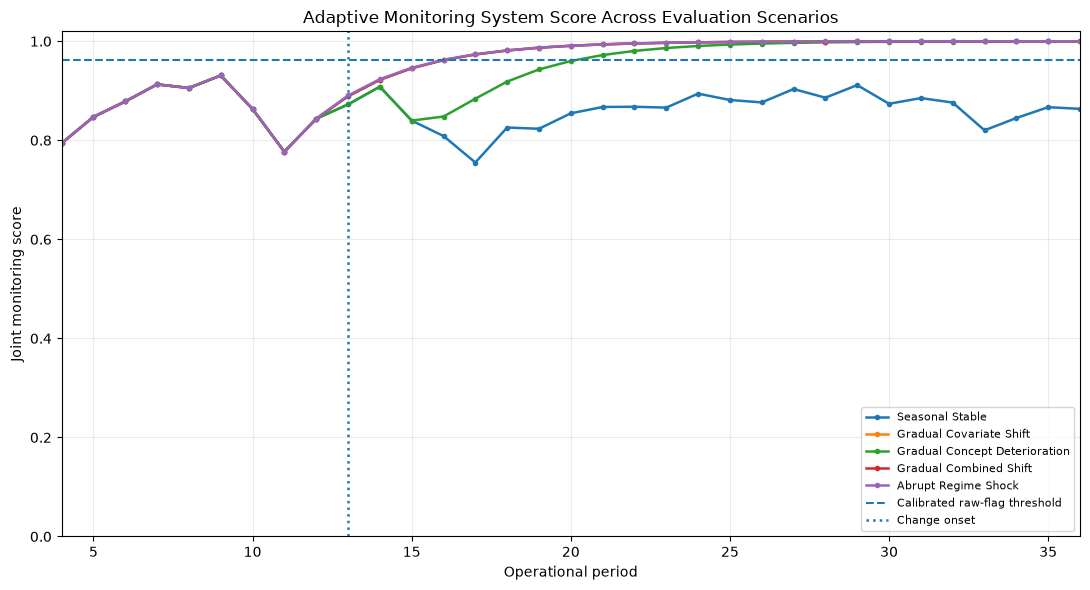

Saved figure: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\adaptive_monitoring_system_score.png
File exists: True


In [209]:
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

fig, ax = plt.subplots(
    figsize=(11, 6)
)

for path_name, path_data in evaluation_paths.items():
    path_results = (
        evaluation_joint.loc[
            evaluation_joint["path"]
            == path_name
        ]
        .sort_values(
            "operational_period"
        )
    )

    ax.plot(
        path_results[
            "operational_period"
        ],
        path_results[
            "system_score"
        ],
        marker="o",
        markersize=3,
        linewidth=1.8,
        label=path_data["label"],
    )


ax.axhline(
    system_score_threshold,
    linestyle="--",
    linewidth=1.5,
    label="Calibrated raw-flag threshold",
)

ax.axvline(
    DRIFT_ONSET_PERIOD,
    linestyle=":",
    linewidth=1.8,
    label="Change onset",
)

ax.set_xlabel(
    "Operational period"
)

ax.set_ylabel(
    "Joint monitoring score"
)

ax.set_title(
    "Adaptive Monitoring System Score Across Evaluation Scenarios"
)

ax.set_xlim(
    4,
    N_PERIODS,
)

ax.set_ylim(
    0,
    1.02,
)

ax.grid(
    alpha=0.25
)

ax.legend(
    loc="lower right",
    fontsize=8,
)

fig.tight_layout()


system_score_figure_path = (
    FIGURES_DIR
    / "adaptive_monitoring_system_score.png"
)

fig.savefig(
    system_score_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved figure:",
    system_score_figure_path,
)

print(
    "File exists:",
    system_score_figure_path.exists(),
)

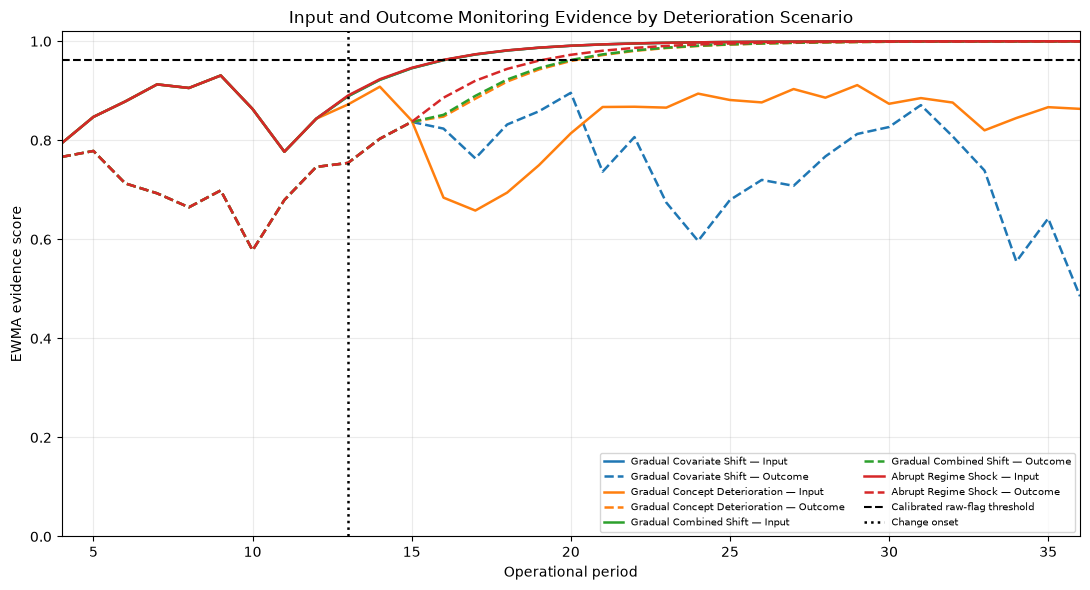

Saved figure: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\adaptive_monitoring_channel_evidence.png
File exists: True


In [210]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

diagnostic_paths = [
    "covariate_shift",
    "concept_deterioration",
    "combined_shift",
    "regime_shock",
]

for path_name in diagnostic_paths:
    path_data = evaluation_paths[
        path_name
    ]

    path_results = (
        evaluation_joint.loc[
            evaluation_joint["path"]
            == path_name
        ]
        .sort_values(
            "operational_period"
        )
    )

    line = ax.plot(
        path_results[
            "operational_period"
        ],
        path_results[
            "input_ewma"
        ],
        linewidth=1.8,
        label=(
            f"{path_data['label']} — Input"
        ),
    )[0]

    ax.plot(
        path_results[
            "operational_period"
        ],
        path_results[
            "outcome_ewma"
        ],
        linewidth=1.8,
        linestyle="--",
        color=line.get_color(),
        label=(
            f"{path_data['label']} — Outcome"
        ),
    )


ax.axhline(
    system_score_threshold,
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Calibrated raw-flag threshold",
)

ax.axvline(
    DRIFT_ONSET_PERIOD,
    linestyle=":",
    linewidth=1.8,
    color="black",
    label="Change onset",
)

ax.set_xlabel(
    "Operational period"
)

ax.set_ylabel(
    "EWMA evidence score"
)

ax.set_title(
    "Input and Outcome Monitoring Evidence by Deterioration Scenario"
)

ax.set_xlim(
    4,
    N_PERIODS,
)

ax.set_ylim(
    0,
    1.02,
)

ax.grid(
    alpha=0.25
)

ax.legend(
    loc="lower right",
    fontsize=7,
    ncol=2,
)

fig.tight_layout()


channel_evidence_figure_path = (
    FIGURES_DIR
    / "adaptive_monitoring_channel_evidence.png"
)

fig.savefig(
    channel_evidence_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved figure:",
    channel_evidence_figure_path,
)

print(
    "File exists:",
    channel_evidence_figure_path.exists(),
)

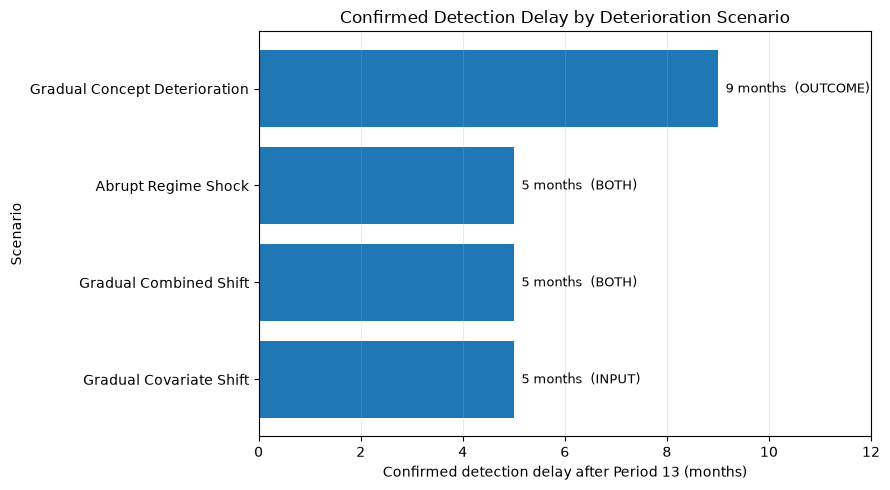

Saved figure: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\adaptive_monitoring_detection_delay.png
File exists: True


In [211]:
detection_plot_data = (
    evaluation_results.loc[
        evaluation_results[
            "path"
        ] != "stable"
    ]
    .copy()
)

detection_plot_data = (
    detection_plot_data
    .sort_values(
        "detection_delay",
        ascending=True,
    )
)


fig, ax = plt.subplots(
    figsize=(9, 5)
)

bars = ax.barh(
    detection_plot_data[
        "path_label"
    ],
    detection_plot_data[
        "detection_delay"
    ],
)


for bar, (_, row) in zip(
    bars,
    detection_plot_data.iterrows(),
):
    ax.text(
        bar.get_width() + 0.15,
        bar.get_y()
        + bar.get_height() / 2,
        (
            f"{int(row['detection_delay'])} months"
            f"  ({row['confirmed_detection_source']})"
        ),
        va="center",
        fontsize=9,
    )


ax.set_xlabel(
    "Confirmed detection delay after Period 13 (months)"
)

ax.set_ylabel(
    "Scenario"
)

ax.set_title(
    "Confirmed Detection Delay by Deterioration Scenario"
)

ax.set_xlim(
    0,
    detection_plot_data[
        "detection_delay"
    ].max() + 3,
)

ax.grid(
    axis="x",
    alpha=0.25,
)

fig.tight_layout()


detection_delay_figure_path = (
    FIGURES_DIR
    / "adaptive_monitoring_detection_delay.png"
)

fig.savefig(
    detection_delay_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved figure:",
    detection_delay_figure_path,
)

print(
    "File exists:",
    detection_delay_figure_path.exists(),
)

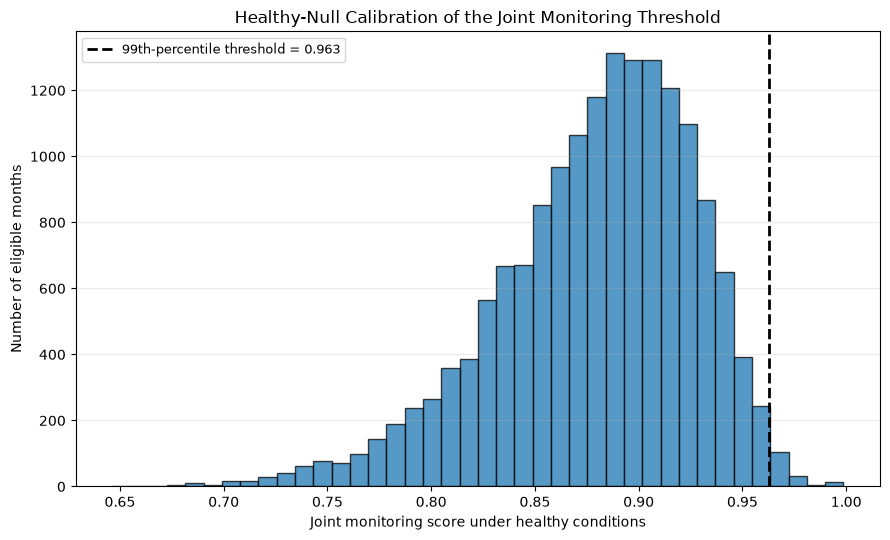

Saved figure: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\adaptive_monitoring_null_threshold.png
File exists: True


In [212]:
fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.hist(
    system_calibration_joint[
        "system_score"
    ],
    bins=40,
    edgecolor="black",
    alpha=0.75,
)

ax.axvline(
    system_score_threshold,
    linestyle="--",
    linewidth=2,
    color="black",
    label=(
        f"99th-percentile threshold = "
        f"{system_score_threshold:.3f}"
    ),
)

ax.set_xlabel(
    "Joint monitoring score under healthy conditions"
)

ax.set_ylabel(
    "Number of eligible months"
)

ax.set_title(
    "Healthy-Null Calibration of the Joint Monitoring Threshold"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    fontsize=9,
)

fig.tight_layout()


null_threshold_figure_path = (
    FIGURES_DIR
    / "adaptive_monitoring_null_threshold.png"
)

fig.savefig(
    null_threshold_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved figure:",
    null_threshold_figure_path,
)

print(
    "File exists:",
    null_threshold_figure_path.exists(),
)

In [213]:
unemployment_psi_null_final = (
    null_input_2000.loc[
        null_input_2000["feature"]
        == "unemployment_rate"
    ]
    .groupby(
        "calendar_month"
    )["psi"]
    .agg(
        mean="mean",
        q99=lambda x: np.quantile(
            x,
            0.99,
        ),
    )
    .reset_index()
)

In [214]:
stable_unemployment_psi = (
    input_drift_summary.loc[
        (
            input_drift_summary["path"]
            == "stable"
        )
        & (
            input_drift_summary["feature"]
            == "unemployment_rate"
        )
    ]
    .groupby(
        "calendar_month"
    )["psi"]
    .mean()
    .reset_index(
        name="stable_mean_psi"
    )
)

In [215]:
seasonality_psi_plot_data = (
    unemployment_psi_null_final
    .merge(
        stable_unemployment_psi,
        on="calendar_month",
        how="left",
    )
)

seasonality_psi_plot_data

,calendar_month,mean,q99,stable_mean_psi
0,1,0.003151,0.007408,0.001700
1,2,0.093346,0.120881,0.097000
2,3,0.267377,0.313872,0.270889
3,4,0.353611,0.406484,0.361085
4,5,0.267225,0.313423,0.267424
5,6,0.093168,0.120764,0.091003
6,7,0.003137,0.007628,0.004428
7,8,0.086714,0.113555,0.092200
8,9,0.256092,0.302126,0.264128
9,10,0.339857,0.394481,0.335881


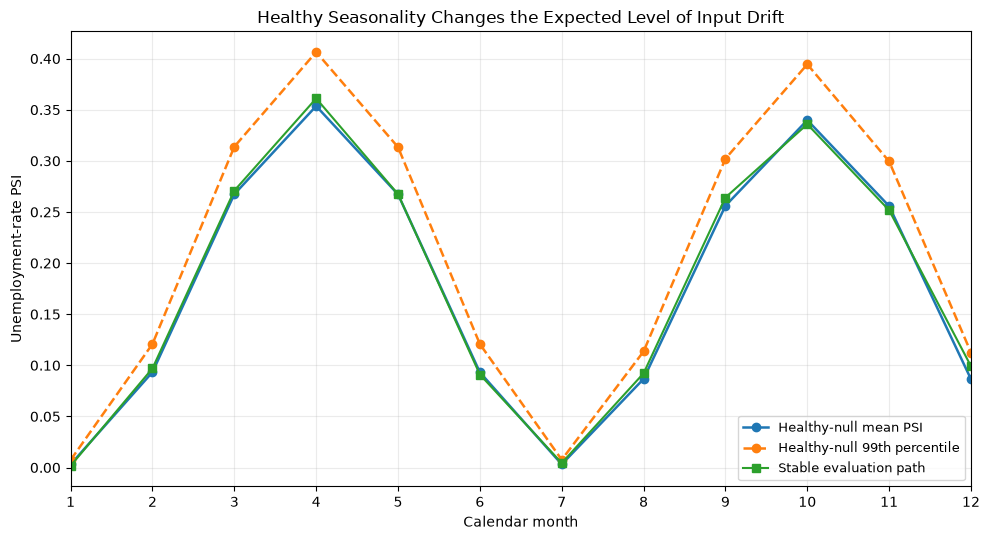

Saved figure: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\adaptive_monitoring_seasonality_psi.png
File exists: True


In [216]:
fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

ax.plot(
    seasonality_psi_plot_data[
        "calendar_month"
    ],
    seasonality_psi_plot_data[
        "mean"
    ],
    marker="o",
    linewidth=1.8,
    label="Healthy-null mean PSI",
)

ax.plot(
    seasonality_psi_plot_data[
        "calendar_month"
    ],
    seasonality_psi_plot_data[
        "q99"
    ],
    marker="o",
    linestyle="--",
    linewidth=1.8,
    label="Healthy-null 99th percentile",
)

ax.plot(
    seasonality_psi_plot_data[
        "calendar_month"
    ],
    seasonality_psi_plot_data[
        "stable_mean_psi"
    ],
    marker="s",
    linewidth=1.5,
    label="Stable evaluation path",
)


ax.set_xlabel(
    "Calendar month"
)

ax.set_ylabel(
    "Unemployment-rate PSI"
)

ax.set_title(
    "Healthy Seasonality Changes the Expected Level of Input Drift"
)

ax.set_xticks(
    range(1, MONTHS_PER_YEAR + 1)
)

ax.set_xlim(
    1,
    MONTHS_PER_YEAR,
)

ax.grid(
    alpha=0.25
)

ax.legend(
    fontsize=9,
)

fig.tight_layout()


seasonality_figure_path = (
    FIGURES_DIR
    / "adaptive_monitoring_seasonality_psi.png"
)

fig.savefig(
    seasonality_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved figure:",
    seasonality_figure_path,
)

print(
    "File exists:",
    seasonality_figure_path.exists(),
)

In [217]:
concept_performance_plot = (
    outcome_performance.loc[
        outcome_performance["path"]
        == "concept_deterioration"
    ]
    .sort_values(
        "cohort_period"
    )
)

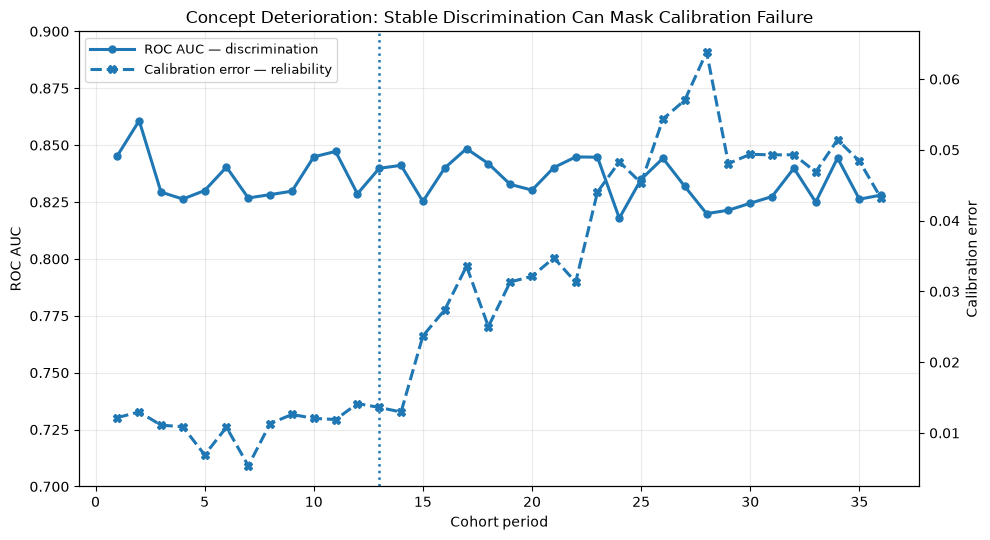

Saved figure: c:\Users\Omid Elmi\Documents\GitHub\adaptive-model-risk\figures\adaptive_monitoring_auc_vs_calibration.png
File exists: True


In [219]:
fig, ax1 = plt.subplots(
    figsize=(10, 5.5)
)

auc_line = ax1.plot(
    concept_performance_plot[
        "cohort_period"
    ],
    concept_performance_plot[
        "roc_auc"
    ],
    marker="o",
    markersize=5,
    linewidth=2.2,
    linestyle="-",
    label="ROC AUC",
)[0]

ax1.set_xlabel(
    "Cohort period"
)

ax1.set_ylabel(
    "ROC AUC"
)

ax1.set_ylim(
    0.70,
    0.90,
)

ax1.axvline(
    DRIFT_ONSET_PERIOD,
    linestyle=":",
    linewidth=1.8,
)

ax1.grid(
    alpha=0.25
)


ax2 = ax1.twinx()

calibration_line = ax2.plot(
    concept_performance_plot[
        "cohort_period"
    ],
    concept_performance_plot[
        "calibration_error"
    ],
    marker="X",
    markersize=6,
    linewidth=2.2,
    linestyle="--",
    label="Calibration error",
)[0]

ax2.set_ylabel(
    "Calibration error"
)


ax1.set_title(
    "Concept Deterioration: Stable Discrimination Can Mask Calibration Failure"
)


ax1.legend(
    [
        auc_line,
        calibration_line,
    ],
    [
        "ROC AUC — discrimination",
        "Calibration error — reliability",
    ],
    loc="upper left",
    fontsize=9,
    handlelength=3.5,
)


fig.tight_layout()


discrimination_calibration_figure_path = (
    FIGURES_DIR
    / "adaptive_monitoring_auc_vs_calibration.png"
)

fig.savefig(
    discrimination_calibration_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()


print(
    "Saved figure:",
    discrimination_calibration_figure_path,
)

print(
    "File exists:",
    discrimination_calibration_figure_path.exists(),
)

### Discrimination can remain stable while calibration deteriorates

The concept-deterioration scenario changes the relationship between borrower characteristics and default risk without changing the distribution of model inputs. As deterioration progresses, the frozen model increasingly underestimates the true level of risk.

ROC AUC remains comparatively stable because the model can still rank higher-risk borrowers above lower-risk borrowers reasonably well. In contrast, calibration error increases as the predicted probabilities become less representative of realized default risk.

This illustrates an important monitoring distinction: **stable discrimination does not imply that predicted probabilities remain reliable**. A monitoring framework that relies primarily on ranking metrics such as ROC AUC may therefore fail to identify meaningful deterioration in the model's probability estimates.

For this reason, ROC AUC is retained as a diagnostic metric in this experiment, while calibration-based evidence contributes directly to the outcome-monitoring channel.

## Key Findings

The adaptive monitoring experiment produced five main findings.

**1. Expected input drift is not necessarily abnormal drift.**
Healthy seasonality generated substantial changes in raw input-drift statistics, particularly for unemployment rate. The healthy-null simulations showed that the expected PSI distribution varies materially by calendar month. This supports the use of calendar-aware empirical normalization rather than fixed drift thresholds applied uniformly throughout the year.

**2. Population shift and model deterioration produce different monitoring signatures.**
The gradual covariate-shift scenario was detected through the input-monitoring channel, while its outcome-calibration evidence remained comparatively weak. In contrast, the pure concept-deterioration scenario produced no abnormal input evidence and was detected only through delayed outcome evidence. This distinction demonstrates that changes in \(P(X)\) should not automatically be interpreted as deterioration in \(P(Y\mid X)\).

**3. Combined monitoring provides diagnostic information, not only alerts.**
The combined-shift and abrupt regime-shock scenarios eventually produced confirmed evidence in both monitoring channels. Input evidence appeared first, followed later by outcome evidence as labels became available. The framework can therefore distinguish input-only, outcome-only, and combined deterioration patterns.

**4. Label delay materially affects detection of concept deterioration.**
The first affected concept-deterioration cohort occurred at Period 13, but its outcomes were not available until Period 16 because of the three-month label delay. The system produced a confirmed outcome alert at Period 22. Thus, the total nine-month detection delay consisted of the label delay plus additional statistical latency required for persistent evidence to accumulate.

**5. Stable discrimination can coexist with deteriorating probability reliability.**
Under concept deterioration, ROC AUC remained comparatively stable while calibration error increased. The model therefore continued to rank borrowers reasonably well even as its predicted probabilities became increasingly unreliable. This is why ROC AUC was retained as a diagnostic metric rather than used as a primary alert component.

### Detection Summary

The Seasonal Stable path produced no confirmed alert in the evaluation trajectory. Gradual Covariate Shift, Gradual Combined Shift, and Abrupt Regime Shock were first confirmed at Period 18, five periods after change onset. Gradual Concept Deterioration was first confirmed at Period 22, nine periods after onset.

For the gradual scenarios, Covariate Shift and Combined Shift were detected when the imposed change had reached approximately 50% of its mature magnitude. Concept Deterioration was not confirmed until the structural change had reached approximately 83% of its mature magnitude.

The monitoring diagnosis was also consistent with the experimental construction:

* **Seasonal Stable:** no confirmed channel;
* **Gradual Covariate Shift:** input evidence only;
* **Gradual Concept Deterioration:** outcome evidence only;
* **Gradual Combined Shift:** input and outcome evidence;
* **Abrupt Regime Shock:** input and outcome evidence.

These results support the central design principle of the experiment: **input drift, model deterioration, and predictive-performance deterioration are related but distinct monitoring problems and should not be treated as interchangeable signals.**

## Final Validation

The following checks verify that the completed experiment is internally consistent, that the monitoring outputs have the expected dimensions, and that the principal result figures were successfully saved.

In [220]:
# Core experiment structure
assert len(evaluation_paths) == 5
assert N_PERIODS == 36
assert DRIFT_ONSET_PERIOD == 13
assert LABEL_DELAY == 3

# Final evaluation tables
assert cohort_summary.shape[0] == 5 * N_PERIODS
assert input_drift_summary.shape[0] == (
    5 * N_PERIODS * len(MODEL_FEATURES)
)
assert outcome_performance.shape[0] == (
    5 * N_PERIODS
)

# Final operational System C timeline
assert evaluation_joint["path"].nunique() == 5

assert (
    evaluation_joint.groupby("path").size()
    == 33
).all()

assert (
    evaluation_joint["operational_period"].min()
    == 4
)

assert (
    evaluation_joint["operational_period"].max()
    == 36
)

# Final null calibration
assert N_NULL_TRAJECTORIES == 2000

assert (
    component_null_input[
        "trajectory_id"
    ].nunique()
    == 1500
)

assert (
    system_calibration_null_input[
        "trajectory_id"
    ].nunique()
    == 500
)

assert 0 < system_score_threshold < 1

# Percentile transformations
for column in [
    "psi_percentile",
    "ks_percentile",
    "wasserstein_percentile",
]:
    assert evaluation_input_final[
        column
    ].between(0, 1).all()

for column in [
    "absolute_gap_percentile",
    "calibration_error_percentile",
    "brier_percentile",
]:
    assert evaluation_outcome_final[
        column
    ].between(0, 1).all()

# Evaluation-result integrity
assert len(evaluation_results) == 5

assert (
    evaluation_results["path"].nunique()
    == 5
)

assert not evaluation_results.loc[
    evaluation_results["path"] == "stable",
    "false_alarm_occurred",
].iloc[0]

assert not evaluation_results.loc[
    evaluation_results["path"] == "stable",
    "post_onset_detection_occurred",
].iloc[0]

for path_name in [
    "covariate_shift",
    "concept_deterioration",
    "combined_shift",
    "regime_shock",
]:
    assert evaluation_results.loc[
        evaluation_results["path"]
        == path_name,
        "post_onset_detection_occurred",
    ].iloc[0]

    assert not evaluation_results.loc[
        evaluation_results["path"]
        == path_name,
        "missed_detection",
    ].iloc[0]

# Final figures
expected_figure_paths = [
    FIGURES_DIR
    / "adaptive_monitoring_system_score.png",

    FIGURES_DIR
    / "adaptive_monitoring_channel_evidence.png",

    FIGURES_DIR
    / "adaptive_monitoring_detection_delay.png",

    FIGURES_DIR
    / "adaptive_monitoring_null_threshold.png",

    FIGURES_DIR
    / "adaptive_monitoring_seasonality_psi.png",

    FIGURES_DIR
    / "adaptive_monitoring_auc_vs_calibration.png",
]

for figure_path in expected_figure_paths:
    assert figure_path.exists(), (
        f"Missing figure: {figure_path}"
    )


print(
    "Final Notebook 3 validation passed."
)

print(
    f"Paths evaluated: "
    f"{evaluation_results['path'].nunique()}"
)

print(
    f"Eligible operational rows: "
    f"{len(evaluation_joint)}"
)

print(
    f"Final system threshold: "
    f"{system_score_threshold:.6f}"
)

print(
    f"Saved result figures: "
    f"{len(expected_figure_paths)}"
)

Final Notebook 3 validation passed.
Paths evaluated: 5
Eligible operational rows: 165
Final system threshold: 0.962926
Saved result figures: 6
